<p style="text-align:center; font-size: 28px;">AI in Health Technologies (2026)</p>
<p style="text-align:center; font-size: 28px;">Project: Source or clinical content?</p>
<p style="text-align:center; font-size: 20px;">Alexandra Dahlberg, Heidi Tarkiainen, Joonatan Syrjänen</p>

### Table of Contents

* [1. Introduction](#section_1)
* [2. Setup](#section_2)
* [3. Data](#section_3)
* [4. Embeddings](#section_4)
* [5. Pictures](#section_5)
    * [5.1. PCA](#section_5_1)
    * [5.2. t-SNE](#section_5_2)
    * [5.3. UMAP](#section_5_3)
    * [5.4. Notes vs imaging texts](#section_5_4)
* [6. Q1: Do the notes separate by text type?](#section_6)
* [7. Classifiers](#section_7)
* [8. Q2: Does the picture predict how hard a diagnosis is?](#section_8)
* [9. Seeds and UMAP settings](#section_9)
* [10. Note type and diagnosis mixed up?](#section_10)
* [11. Clinical review](#section_11)
* [12. Package versions](#section_12)

## 1. Introduction <a class="anchor" id="section_1"></a>

A language model turns each clinical note into an embedding, a long list of numbers. PCA, t-SNE and UMAP squeeze these into a 2-D picture where similar notes end up close together. In earlier work on lung imaging reports, our group saw that these pictures split clearly by note type but not by cancer diagnosis. That worries us: if a model can tell what kind of note it is reading, anything trained on top of it might learn the note type instead of the disease.

So we looked at vascular surgery notes from one EHR (Apotti) and asked two questions:

- **Q1:** Do the notes separate by text type (note type, specialty, year) rather than by what they say?
- **Q2:** Do they separate by diagnosis, and does the picture tell us how hard a diagnosis classifier will find the task?

We did not want to trust the pictures alone, so we checked each one with numbers in the full embedding space.

We built everything on synthetic notes first, with structure planted on purpose, and then ran the same notebook on the real notes in HUS Acamedic. Only numbers and figures left Acamedic, never text.

**Running it.** On the synthetic data the notebook runs from top to bottom without Ollama, because the embeddings are saved in `embeddings/`. In Colab, the first code cell gets the repo and installs `umap-learn`.

## 2. Setup <a class="anchor" id="section_2"></a>

In [1]:
# Packages
import os
import re
import sys
import warnings
from importlib.metadata import version
warnings.filterwarnings("ignore", category=FutureWarning) # Notices about future package versions, they did not change the results

# In Colab we first had to get the repo and umap-learn
if "google.colab" in sys.modules:
    os.system("pip install umap-learn")
    os.system("git clone https://github.com/joonatansyrjanen/finnish-clinical-note-embeddings")
    os.chdir("finnish-clinical-note-embeddings")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy import stats

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score, silhouette_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors
import umap # pip install umap-learn

import torch
from torch import nn

In [2]:
# Synthetic data here, real data in Acamedic
data_source = "synthetic" # We changed this to "real" in Acamedic

if data_source == "synthetic":
    data_folder = "mock_data"
else:
    data_folder = "path/to/acamedic/import/" # The real path inside Acamedic is not shared

# Embedding model, run through Ollama
model_name = "bge-m3"
ollama_model = "bge-m3:567m"
ollama_url = "http://localhost:11434" # In Acamedic this pointed to the Azure ML compute
max_tokens = 8192 # BGE-M3 reads up to 8192 tokens, but Ollama cuts at 2048 unless we tell it otherwise

# Settings we fixed before looking at the real data
seed = 42
k = 15 # Neighbours in the kNN agreement
min_characters = 40 # Shorter notes were dropped
max_notes = 20000 # Random patients until about this many notes, embedding all 745 000 would take about 40 hours
min_patients_per_code = 10 # Rarer ICD codes were left out of the diagnosis analysis
number_of_folds = 5 # Cross-validation folds grouped by patient, also the inner splits for choosing the epoch
checkpoint_epochs = [10, 25, 50, 100, 200, 500, 1000]
length_checkpoints = checkpoint_epochs + [2000, 5000, 10000, 20000] # Length alone learned more slowly
learning_rate = 0.001 # Constant in both epoch selection and refitting
weight_decay = 0.0001 # Keeps the classifier weights small
hidden_units = 256 # Size of the MLP hidden layer
tfidf_words = 5000 # Most common words kept for the TF-IDF baseline
device = "cuda" if torch.cuda.is_available() else "cpu" # The classifiers ran on the GPU when there was one
seeds = [0, 1, 2, 3, 4] # Random seeds for t-SNE and UMAP, seed 0 is the main picture
umap_neighbours = [5, 15, 50] # UMAP settings, 15 is the main picture
texts_per_table = 2500 # At most this many texts per table in the notes vs imaging picture, like Rami
number_of_clusters = 8 # For the clinical review, we set this after looking at the UMAP
notes_per_cluster = 5 # Notes the clinician read from each cluster
classes_in_legend = 7 # Only the biggest classes get their own colour in the pictures, the rest are "other"

# Labels we coloured the pictures by
labels_to_check = ["note_type", "specialty", "year", "length_quartile", "diagnosis_group", "diagnosis_code"]

# Rami's colours from the lung imaging figures, plus a few lighter ones for labels with many classes
palette = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2", "#EECA3B", "#B279A2", "#FF9DA6", "#9D755D", "#BAB0AC",
           "#9ECAE9", "#FFBF79", "#88D27A", "#83BCB6", "#FF9D98", "#D6A5C9"]
source_colours = {"apotti_kuvantaminen_lausunto": "#4C78A8", # Imaging reports, blue like Rami's
                  "apotti_kuvantaminen_tutkimus": "#F58518", # Imaging requests, orange
                  "apotti_potilaskertomus": "#54A24B"} # Patient record notes, green

# Results that leave Acamedic follow Findata's rules for anonymous results: no count under 3
minimum_count = 3

def masked(count):
    """A count as text, with 1 and 2 shown as "<3". Zero needs no hiding."""
    if 0 < count < minimum_count:
        return "<%d" % minimum_count
    return "%d" % count

def masked_counts(counts):
    """Counts as text with 1 and 2 hidden. If only one is hidden, the next smallest is hidden too, so it cannot be worked out from the total."""
    shown = counts.apply(masked)
    small = (counts > 0) & (counts < minimum_count)
    big = (counts >= minimum_count)
    if small.sum() == 1 and big.sum() > 0:
        shown[counts[big].idxmin()] = "hidden"
    return shown

# Figures and tables go here
results_folder = "results/" + model_name
os.makedirs(results_folder, exist_ok=True)

## 3. Data <a class="anchor" id="section_3"></a>

The texts are the free-text patient record entries (potilaskertomus). Each note got the main ICD-10 diagnosis of its care episode, joined through the episode ID.

Some notes start with a line giving the writer's name and time. Staff names alone give away the hospital, so we removed that line before embedding.

In [3]:
# Notes and diagnoses, both tables use ; as the separator
notes = pd.read_csv(data_folder + "/Apotti_potilaskertomus.csv", sep=";")
diagnoses = pd.read_csv(data_folder + "/Apotti_diagnoosi.csv", sep=";")

# Main diagnosis of each care episode, joined to the notes through the episode ID
main_diagnoses = diagnoses[diagnoses["paadiagnoosi"] == True]
main_diagnoses = main_diagnoses.drop_duplicates(subset="shjakso_id") # A few episodes had the same code twice
notes = notes.merge(main_diagnoses[["shjakso_id", "diagnoosi_koodi"]], on="shjakso_id", how="left")

# Shorter English names for the columns we used
notes["note_id"] = notes["merkinta_id"]
notes["patient_id"] = notes["henkilotunnus"]
notes["note_type"] = notes["merkinta_valilehti_selite"] # E.g. Päivittäismerkintä
notes["specialty"] = notes["toimipiste_eala_selite"] # Specialty of the writing unit
notes["year"] = notes["merkinta_luonti_hetki"].str[:4] # E.g. 2023
notes["diagnosis_code"] = notes["diagnoosi_koodi"] # E.g. I70.2
notes["diagnosis_group"] = notes["diagnoosi_koodi"].str[:3] # E.g. I70

# Header (e.g. "Lisännyt SURNAME, FIRSTNAME 01.01.2000 00:00", sometimes with a role), only if the note starts with one.
# Notes without a header are kept whole.
header_pattern = r"^Lisännyt [^\d]{0,60}\d{1,2}\.\d{1,2}\.\d{4} \d{1,2}:\d{2}\s*"
notes["text"] = notes["merkinta_teksti"].str.replace(header_pattern, "", regex=True)

# The real header has no role, so doctors' notes come from the note type
doctor_note_types = ["Päivittäismerkintä", "Leikkauskertomus", "Anestesia: toimenpidettä edeltävä arviointi"]
notes["doctor"] = notes["note_type"].isin(doctor_note_types)

Very short notes, like "Uusi aika annettu.", say almost nothing, so we dropped them. Next we split note length into four equal groups. That way we could see whether a picture just sorts short notes from long ones (the proposal feedback suggested length as a surface baseline). ICD codes with fewer than 10 patients were left out of the diagnosis analysis, but their notes stayed in.

In [4]:
# Very short notes dropped
notes["characters"] = notes["text"].str.len()
print("Notes shorter than %d characters dropped: %d"
      % (min_characters, np.sum(notes["characters"] < min_characters)))
notes = notes[notes["characters"] >= min_characters]

# Random patients, all their notes, until about max_notes notes.
# Sampling patients rather than notes keeps the cross-validation grouping by patient intact.
patients = notes["patient_id"].drop_duplicates().sample(frac=1, random_state=seed)
notes_per_patient = notes.groupby("patient_id").size()[patients]
kept_patients = patients[notes_per_patient.cumsum().to_numpy() <= max_notes]
notes = notes[notes["patient_id"].isin(kept_patients)]
print(
    "Notes after sampling: %d from %d patients"
    % (notes.shape[0], len(kept_patients))
)

notes = notes.reset_index(drop=True) # Row n of notes is row n of the embeddings

# Note length in four equal groups
notes["length_quartile"] = pd.qcut(notes["characters"], 4, labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"]).astype(str)

# Rare ICD codes and groups left out of the diagnosis analysis
patients_per_code = notes.groupby("diagnosis_code")["patient_id"].nunique()
rare_codes = patients_per_code[patients_per_code < min_patients_per_code].index
notes.loc[notes["diagnosis_code"].isin(rare_codes), "diagnosis_code"] = np.nan

patients_per_group = notes.groupby("diagnosis_group")["patient_id"].nunique()
rare_groups = patients_per_group[patients_per_group < min_patients_per_code].index
notes.loc[notes["diagnosis_group"].isin(rare_groups), "diagnosis_group"] = np.nan

# Most notes from one patient, needed for the kNN agreement in Section 6
most_notes_per_patient = notes.groupby("patient_id").size().max()

# Numbers for Table 1
print("Notes: %d"
      % notes.shape[0])
print("Patients: %d"
      % notes["patient_id"].nunique())
print("ICD-10 codes kept: %d"
      % notes["diagnosis_code"].nunique())

Notes shorter than 40 characters dropped: 585
Notes after sampling: 10443 from 593 patients
Notes: 10443
Patients: 593
ICD-10 codes kept: 12


In the earlier lung work, notes and radiology reports ended up far apart in the pictures. To see the same thing in our data, we also took the imaging reports (lausunto) and imaging requests (tutkimus). As in Rami's figures, we used at most 2500 texts per table.

In [5]:
# Imaging reports and requests
reports_table = pd.read_csv(data_folder + "/Apotti_kuvantaminen_lausunto.csv", sep=";")
requests_table = pd.read_csv(data_folder + "/Apotti_kuvantaminen_tutkimus.csv", sep=";")

reports = pd.DataFrame({"text_id": reports_table["ac_numero"].astype(str) + "_lausunto",
                        "patient_id": reports_table["henkilotunnus"],
                        "source": "apotti_kuvantaminen_lausunto",
                        "text": reports_table["lausunto_teksti"]})
imaging_requests = pd.DataFrame({"text_id": requests_table["maarays_id"].astype(str) + "_pyynto",
                                 "patient_id": requests_table["henkilotunnus"],
                                 "source": "apotti_kuvantaminen_tutkimus",
                                 "text": requests_table["pyynto_teksti"]})

# At most texts_per_table from each table
if reports.shape[0] > texts_per_table:
    reports = reports.sample(n=texts_per_table, random_state=seed)
if imaging_requests.shape[0] > texts_per_table:
    imaging_requests = imaging_requests.sample(n=texts_per_table, random_state=seed)

imaging = pd.concat([reports, imaging_requests], ignore_index=True)
imaging = imaging[imaging["text"].str.len() >= min_characters] # Same rule as for the notes
imaging = imaging.reset_index(drop=True)

print(masked_counts(imaging["source"].value_counts()).to_string()) # Counts under 3 hidden

source
apotti_kuvantaminen_lausunto    900
apotti_kuvantaminen_tutkimus    900


## 4. Embeddings <a class="anchor" id="section_4"></a>

We used BGE-M3, a multilingual model that covers Finnish and reads up to 8192 tokens. We ran it through Ollama, both on our own computers and in Acamedic, so the same code worked in both places. Ollama gives one vector of 1024 numbers per note.

Embedding takes a while, so we saved the vectors in `embeddings/` and loaded them on later runs. To make them again, install Ollama, run `ollama pull bge-m3` in a terminal and delete the `.npy` file.

In [6]:
def embed(text):
    """Sends one text to Ollama and gets back its embedding and the number of tokens it read, or None if it failed."""
    # First with the long context, then once with Ollama's defaults if the result was NaN
    for options in [{"num_ctx": max_tokens, "num_batch": max_tokens}, {}]:
        response = requests.post(ollama_url + "/api/embed", json={
            "model": ollama_model,
            "input": text,
            "options": options, # Without num_ctx and num_batch Ollama cuts every text at 2048 tokens
        })
        answer = response.json()
        if "embeddings" in answer:
            return answer["embeddings"][0], answer["prompt_eval_count"]
    return None, None # Failed twice, e.g. NaN from the model


# Notes, embedded once and then loaded from the file
notes_file = "embeddings/" + model_name + "_no_header.npy"
notes_tokens_file = "embeddings/" + model_name + "_no_header_labels.csv"

if os.path.exists(notes_file):
    embeddings = np.load(notes_file)
    saved = pd.read_csv(notes_tokens_file)
    notes = notes[notes["note_id"].isin(saved["note_id"])].reset_index(drop=True) # Without the notes that failed
    assert saved["note_id"].tolist() == notes["note_id"].tolist(), "The saved embeddings are for other notes, delete the file and embed again"
    notes["tokens"] = saved["tokens"]
    print("Loaded %d embeddings from %s"
          % (embeddings.shape[0], notes_file))
else:
    # First we checked that Ollama really read 8192 tokens, otherwise long notes get cut without any warning
    vector, tokens_read = embed("Potilas voi hyvin. " * 5000)
    print("Tokens read from a very long text: %d (should be %d)"
          % (tokens_read, max_tokens))

    # Then every note, one at a time
    embeddings = []
    tokens = []
    for text in notes["text"]:
        vector, tokens_read = embed(text)
        embeddings.append(vector)
        tokens.append(tokens_read)
        if len(embeddings) % 1000 == 0:
            print("Embedded %d of %d notes"
                  % (len(embeddings), notes.shape[0]))

    # Notes that failed twice were left out
    worked = [vector is not None for vector in embeddings]
    print("Notes that could not be embedded: %d of %d (%.2f%%)"
          % (len(worked) - sum(worked), len(worked), 100 * (len(worked) - sum(worked)) / len(worked)))
    
    embeddings = [vector for vector in embeddings if vector is not None]
    tokens = [count for count in tokens if count is not None]
    notes = notes[worked].reset_index(drop=True) # Row n of notes is still row n of the embeddings
    embeddings = np.array(embeddings)
    notes["tokens"] = tokens
    np.save(notes_file, embeddings)
    notes[["note_id", "tokens"]].to_csv(notes_tokens_file, index=False)

print("Embeddings: %d notes, %d numbers each"
      % embeddings.shape)

Loaded 10443 embeddings from embeddings/bge-m3_no_header.npy
Embeddings: 10443 notes, 1024 numbers each


Notes that could not be embedded: 3 of 19971 (0.02%)

In [7]:
# Imaging reports and requests, the same way
imaging_file = "embeddings/" + model_name + "_imaging.npy"
imaging_tokens_file = "embeddings/" + model_name + "_imaging_labels.csv"

if os.path.exists(imaging_file):
    imaging_embeddings = np.load(imaging_file)
    saved = pd.read_csv(imaging_tokens_file)
    assert saved["text_id"].tolist() == imaging["text_id"].tolist(), "The saved embeddings are for other texts, delete the file and embed again"
    print("Loaded %d embeddings from %s"
          % (imaging_embeddings.shape[0], imaging_file))
else:
    imaging_embeddings = []
    tokens = []
    for text in imaging["text"]:
        vector, tokens_read = embed(text)
        imaging_embeddings.append(vector)
        tokens.append(tokens_read)
    # Texts that failed twice were left out, like the notes
    worked = [vector is not None for vector in imaging_embeddings]
    print("Imaging texts that could not be embedded: %d of %d"
          % (len(worked) - sum(worked), len(worked)))
    imaging_embeddings = np.array([vector for vector in imaging_embeddings if vector is not None])
    imaging["tokens"] = tokens
    imaging = imaging[worked].reset_index(drop=True) # Row n of imaging is still row n of the embeddings
    np.save(imaging_file, imaging_embeddings)
    imaging[["text_id", "tokens"]].to_csv(imaging_tokens_file, index=False)
    print("Embedded %d imaging texts"
          % imaging_embeddings.shape[0])

Loaded 1800 embeddings from embeddings/bge-m3_imaging.npy


The feedback asked how we handled notes over 512 tokens. BGE-M3 reads up to 8192 tokens, so with BGE-M3 nothing was cut.

In [8]:
# How long the notes were, counted with the BGE-M3 tokenizer
print("99th percentile of note length: %d tokens"
      % np.percentile(notes["tokens"], 99)) # A percentile instead of the longest note, which is one note
print("Notes cut at %d tokens by BGE-M3: %d"
      % (max_tokens, np.sum(notes["tokens"] >= max_tokens)))

99th percentile of note length: 747 tokens
Notes cut at 8192 tokens by BGE-M3: 0


## 5. Pictures <a class="anchor" id="section_5"></a>

We made the pictures with PCA, t-SNE and UMAP and coloured each one by every label. PCA is the simple linear one. t-SNE and UMAP try to keep notes that are close in the full space close in the picture too. Their axes have no units, and the distance between two far-apart clusters means very little.

We drew all pictures the same way as Rami's lung figures: his colours, the biggest class first and the number of notes in the legend. This function draws one picture.

In [9]:
def plot_by_label(ax, points, labels, label_name, title):
    """Draws the 2-D points as a square picture, one colour per class, like Rami's figures."""
    labels = pd.Series(list(labels)) # Plain 0, 1, 2... index so it matches the rows of points

    # Text sources keep Rami's colours, other labels get his palette with the biggest class first
    if label_name == "source":
        classes = [name for name in source_colours if name in labels.values]
        colours = dict(source_colours)
    else:
        classes = list(labels.value_counts().index[:classes_in_legend]) # Biggest classes only
        if label_name in ["year", "length_quartile"]:
            classes = sorted(classes) # In order rather than by size
        colours = {}
        for index in range(len(classes)):
            colours[classes[index]] = palette[index % len(palette)]

    # Smaller classes together as "other" (only in the picture, the analyses still use every class),
    # notes without a label (rare ICD codes) as "no label"
    shown = labels.where(labels.isin(classes), "other")
    shown[labels.isnull()] = "no label"
    colours["other"] = "#999999"
    colours["no label"] = "#DDDDDD"
    names = ["no label", "other"] + classes # Grey ones drawn first, underneath
    counts = masked_counts(shown.value_counts()) # Counts for the legend, under 3 hidden

    # One class at a time, with the number of notes in the legend
    for name in names:
        in_class = (shown == name).to_numpy()
        if in_class.sum() == 0:
            continue
        ax.scatter(points[in_class, 0], points[in_class, 1], s=4, alpha=0.7, color=colours[name],
                   label="%s (%s)" % (name, counts[name]))

    ax.set_title(title)
    ax.set_xticks([]) # No units on these axes
    ax.set_yticks([])
    ax.set_box_aspect(1) # Square picture
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False, markerscale=3)

### 5.1. PCA <a class="anchor" id="section_5_1"></a>

Variance explained by the two components: 23.4 %


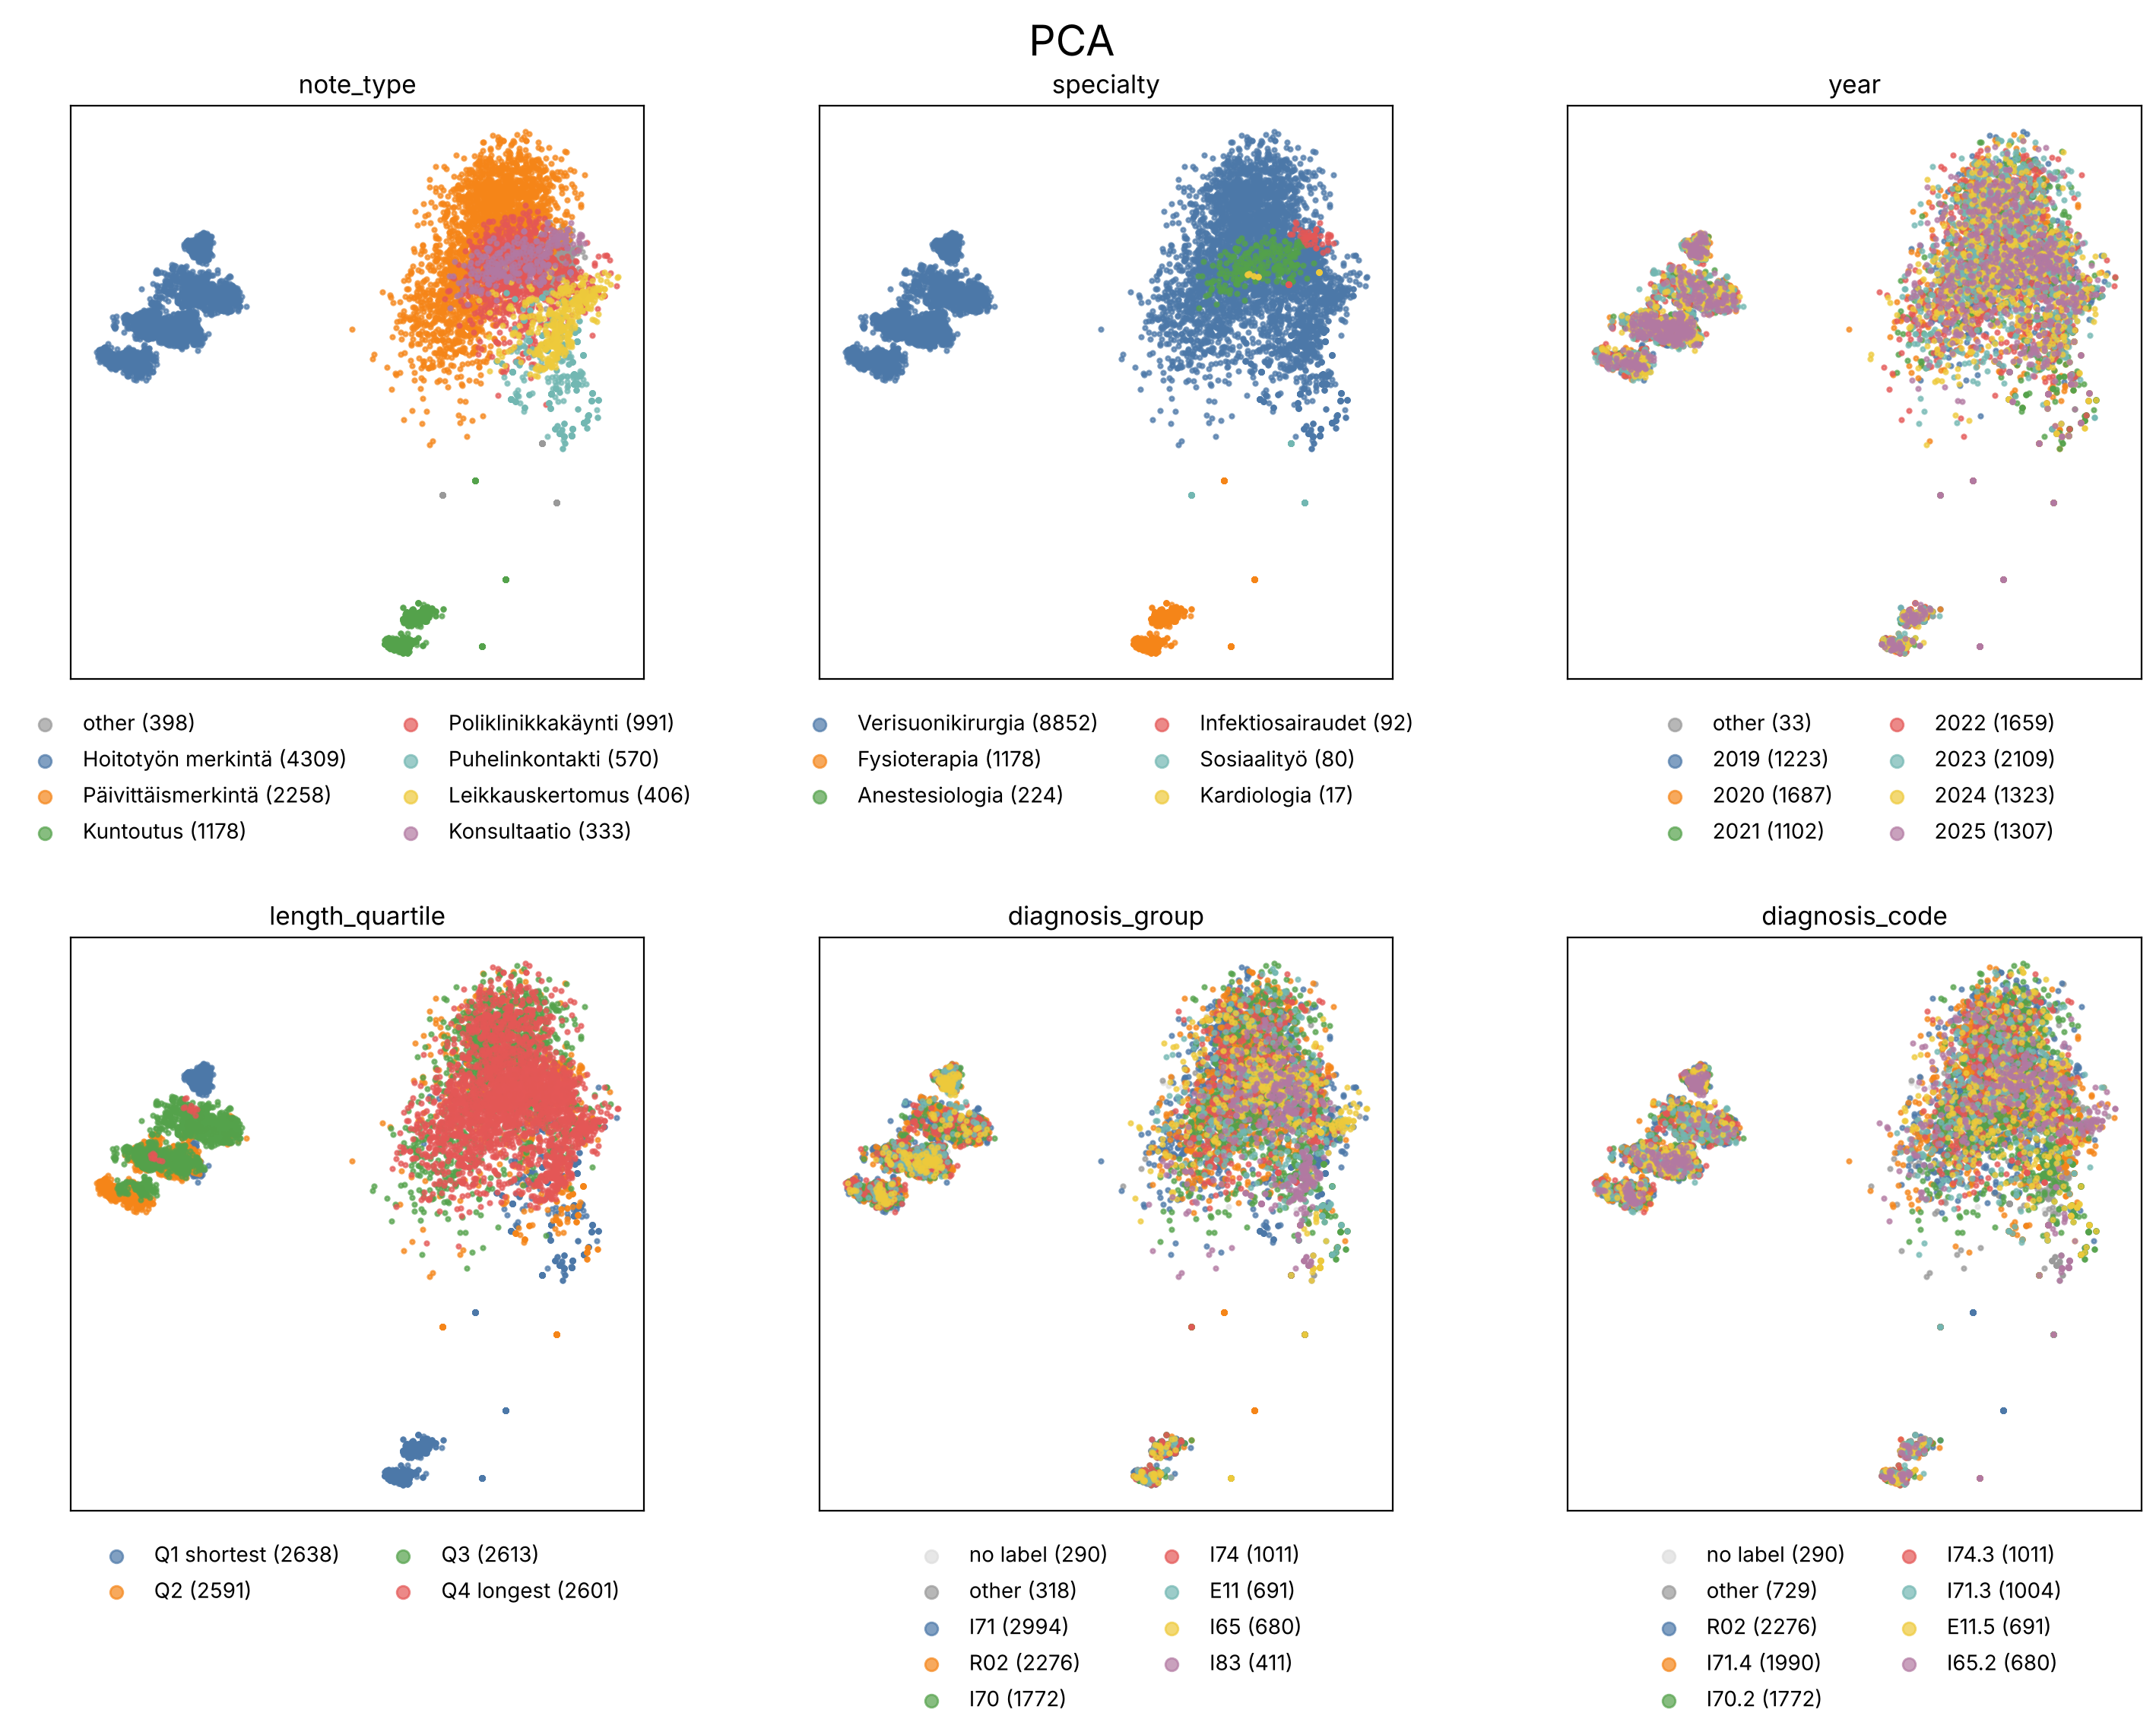

In [10]:
# PCA to 2-D
pca = PCA(n_components=2, random_state=seed)
pca_points = pca.fit_transform(embeddings)
print("Variance explained by the two components: %.1f %%"
      % (100 * np.sum(pca.explained_variance_ratio_)))

# One picture per label
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.subplots_adjust(hspace=0.45) # Room for the legends between the rows
for index in range(len(labels_to_check)):
    label = labels_to_check[index]
    plot_by_label(axes.flat[index], pca_points, notes[label], label, label)
fig.suptitle("PCA", y=0.93, fontsize=20) # Title closer to the pictures, and bigger
fig.savefig(results_folder + "/pca.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2. t-SNE <a class="anchor" id="section_5_2"></a>

We ran t-SNE with five random seeds (cosine distance, perplexity 30, starting from the PCA layout). Seed 0 is the picture we show; the other seeds come back in Section 9.

t-SNE seed 0 done


t-SNE seed 1 done


t-SNE seed 2 done


t-SNE seed 3 done


t-SNE seed 4 done


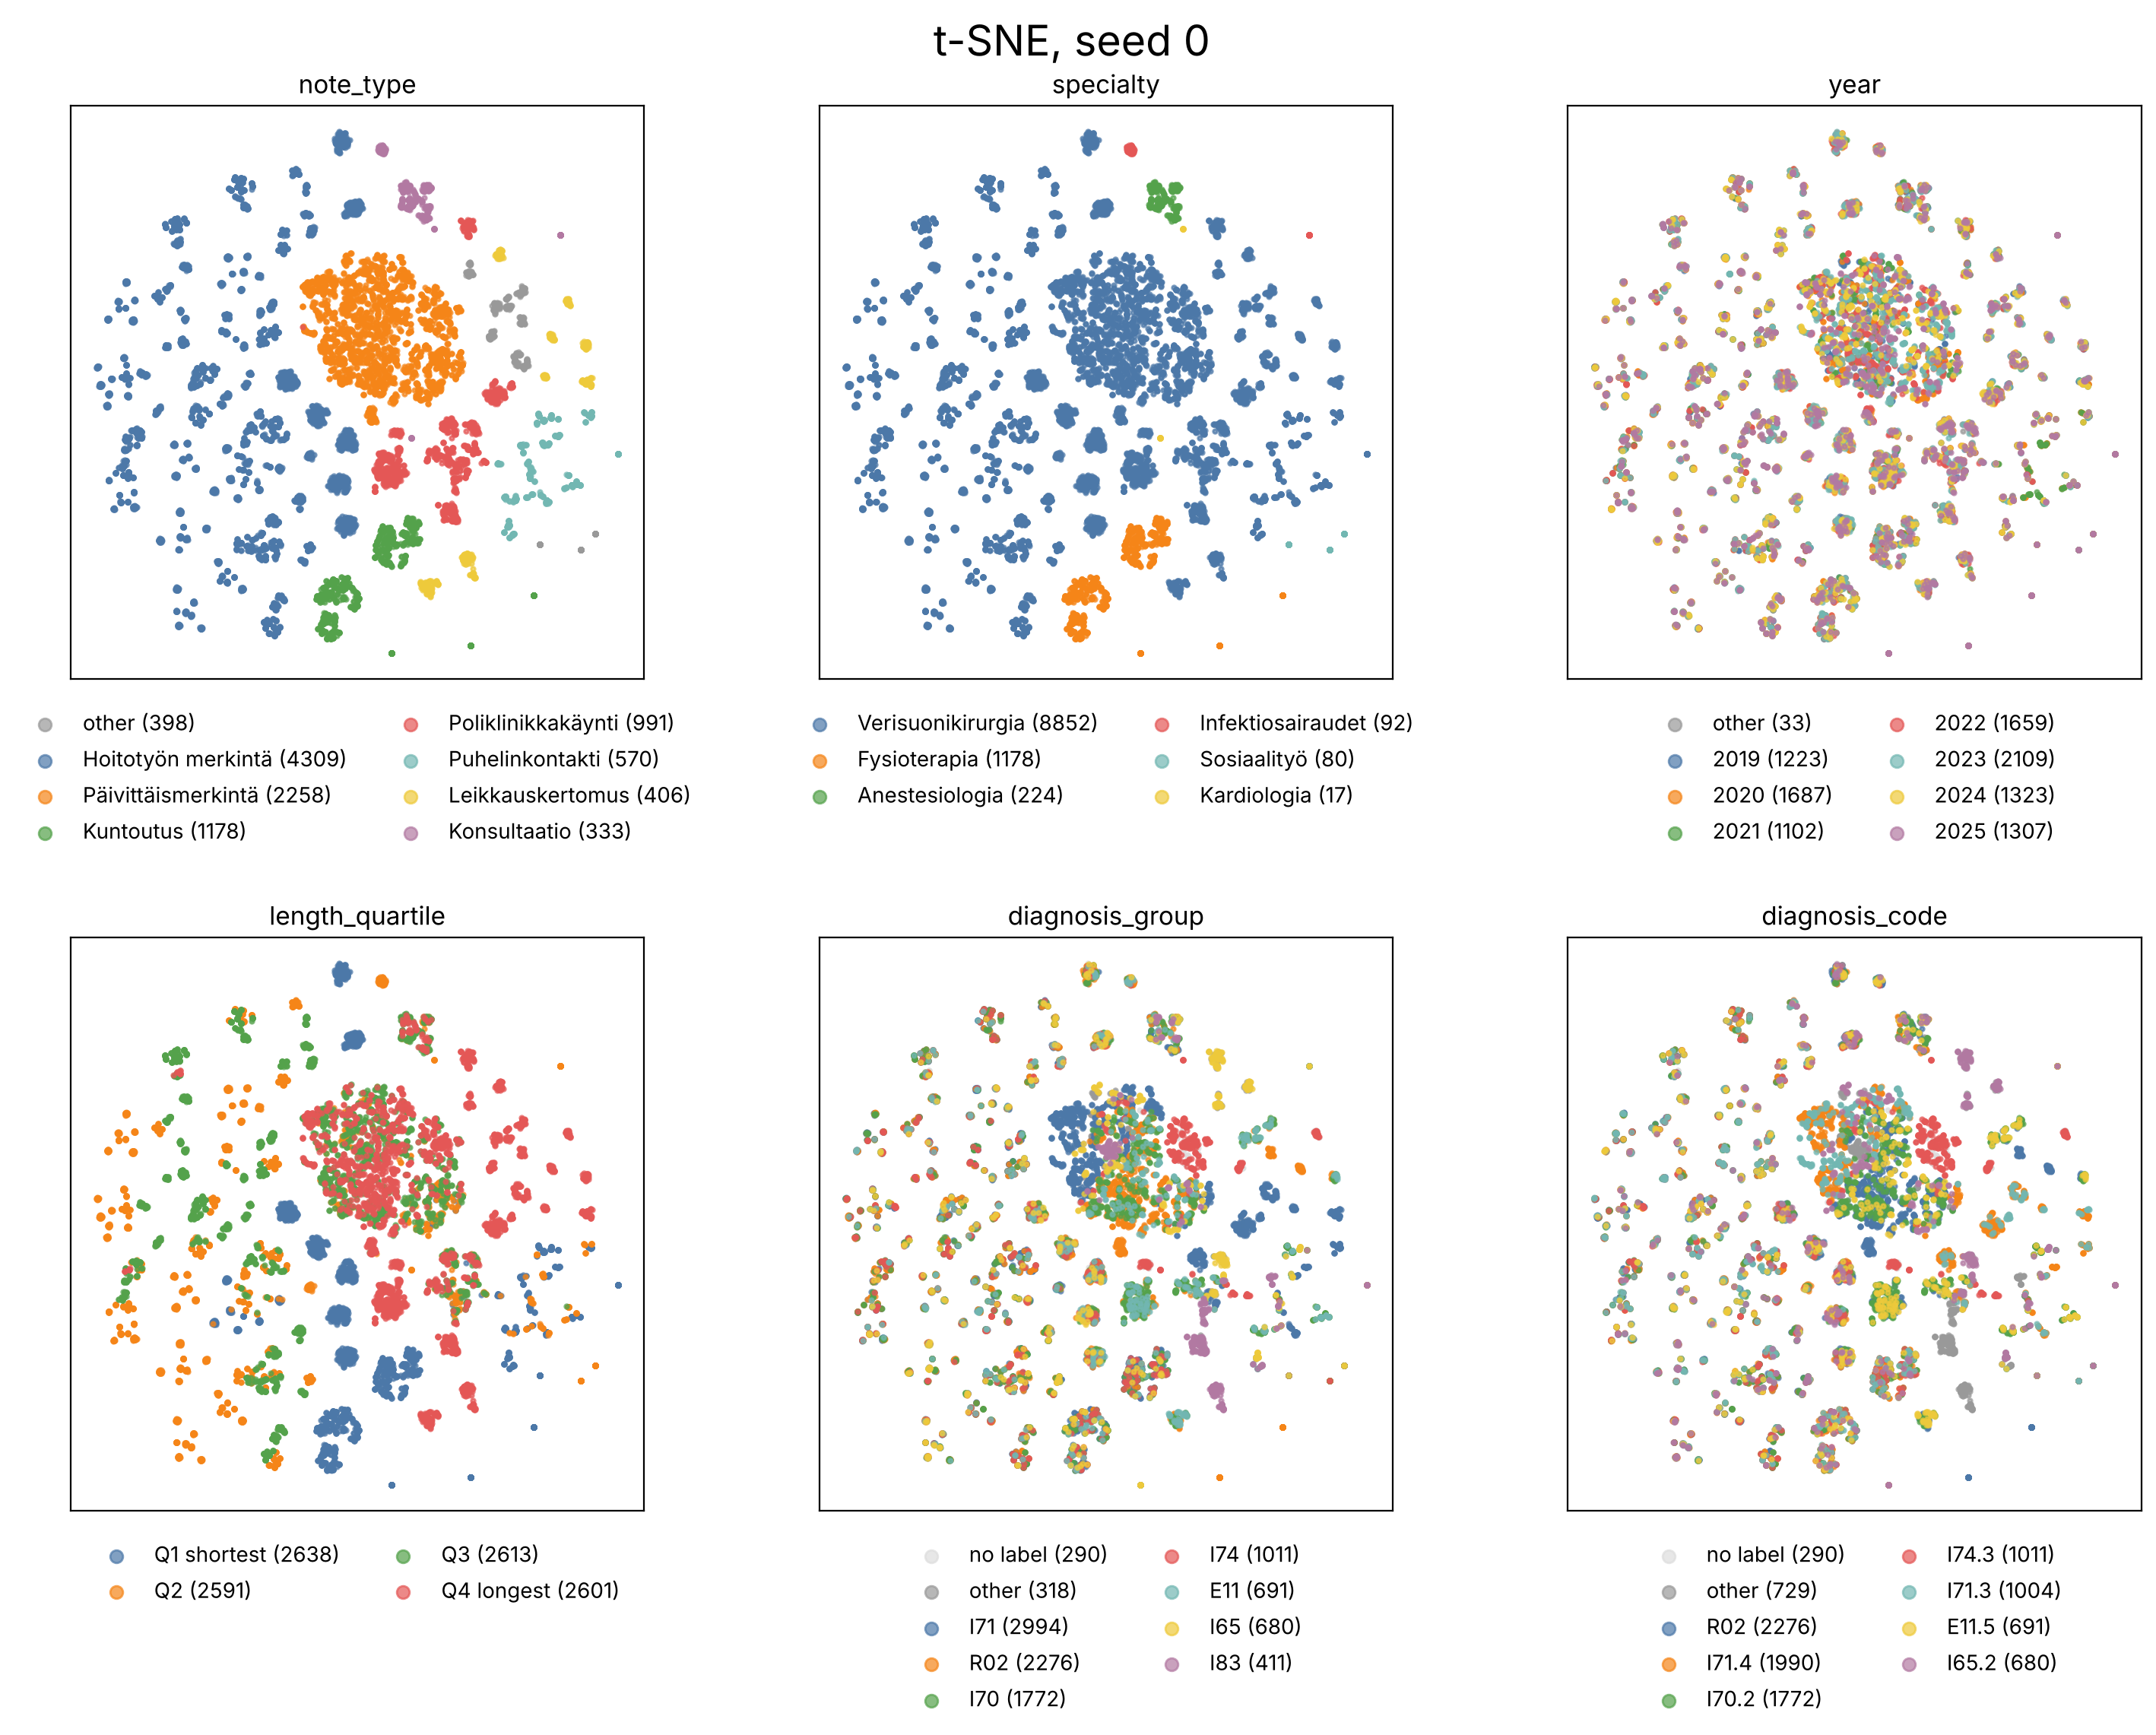

In [11]:
# t-SNE, one run per seed
tsne_points = {}
for projection_seed in seeds:
    tsne = TSNE(metric="cosine", perplexity=30, init="pca", random_state=projection_seed)
    tsne_points[projection_seed] = tsne.fit_transform(embeddings)
    print("t-SNE seed %d done"
          % projection_seed)

# One picture per label, seed 0
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.subplots_adjust(hspace=0.45) # Room for the legends between the rows
for index in range(len(labels_to_check)):
    label = labels_to_check[index]
    plot_by_label(axes.flat[index], tsne_points[0], notes[label], label, label)
fig.suptitle("t-SNE, seed 0", y=0.93, fontsize=20)
fig.savefig(results_folder + "/tsne.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3. UMAP <a class="anchor" id="section_5_3"></a>

UMAP ran with cosine distance and `min_dist` 0.1, starting from the PCA layout. The default start failed on the exact duplicate notes that copy-paste creates. We tried `n_neighbors` 5, 15 and 50 with the same five seeds; `n_neighbors` 15 with seed 0 is the main picture.

UMAP n_neighbors 5 done


UMAP n_neighbors 15 done


UMAP n_neighbors 50 done


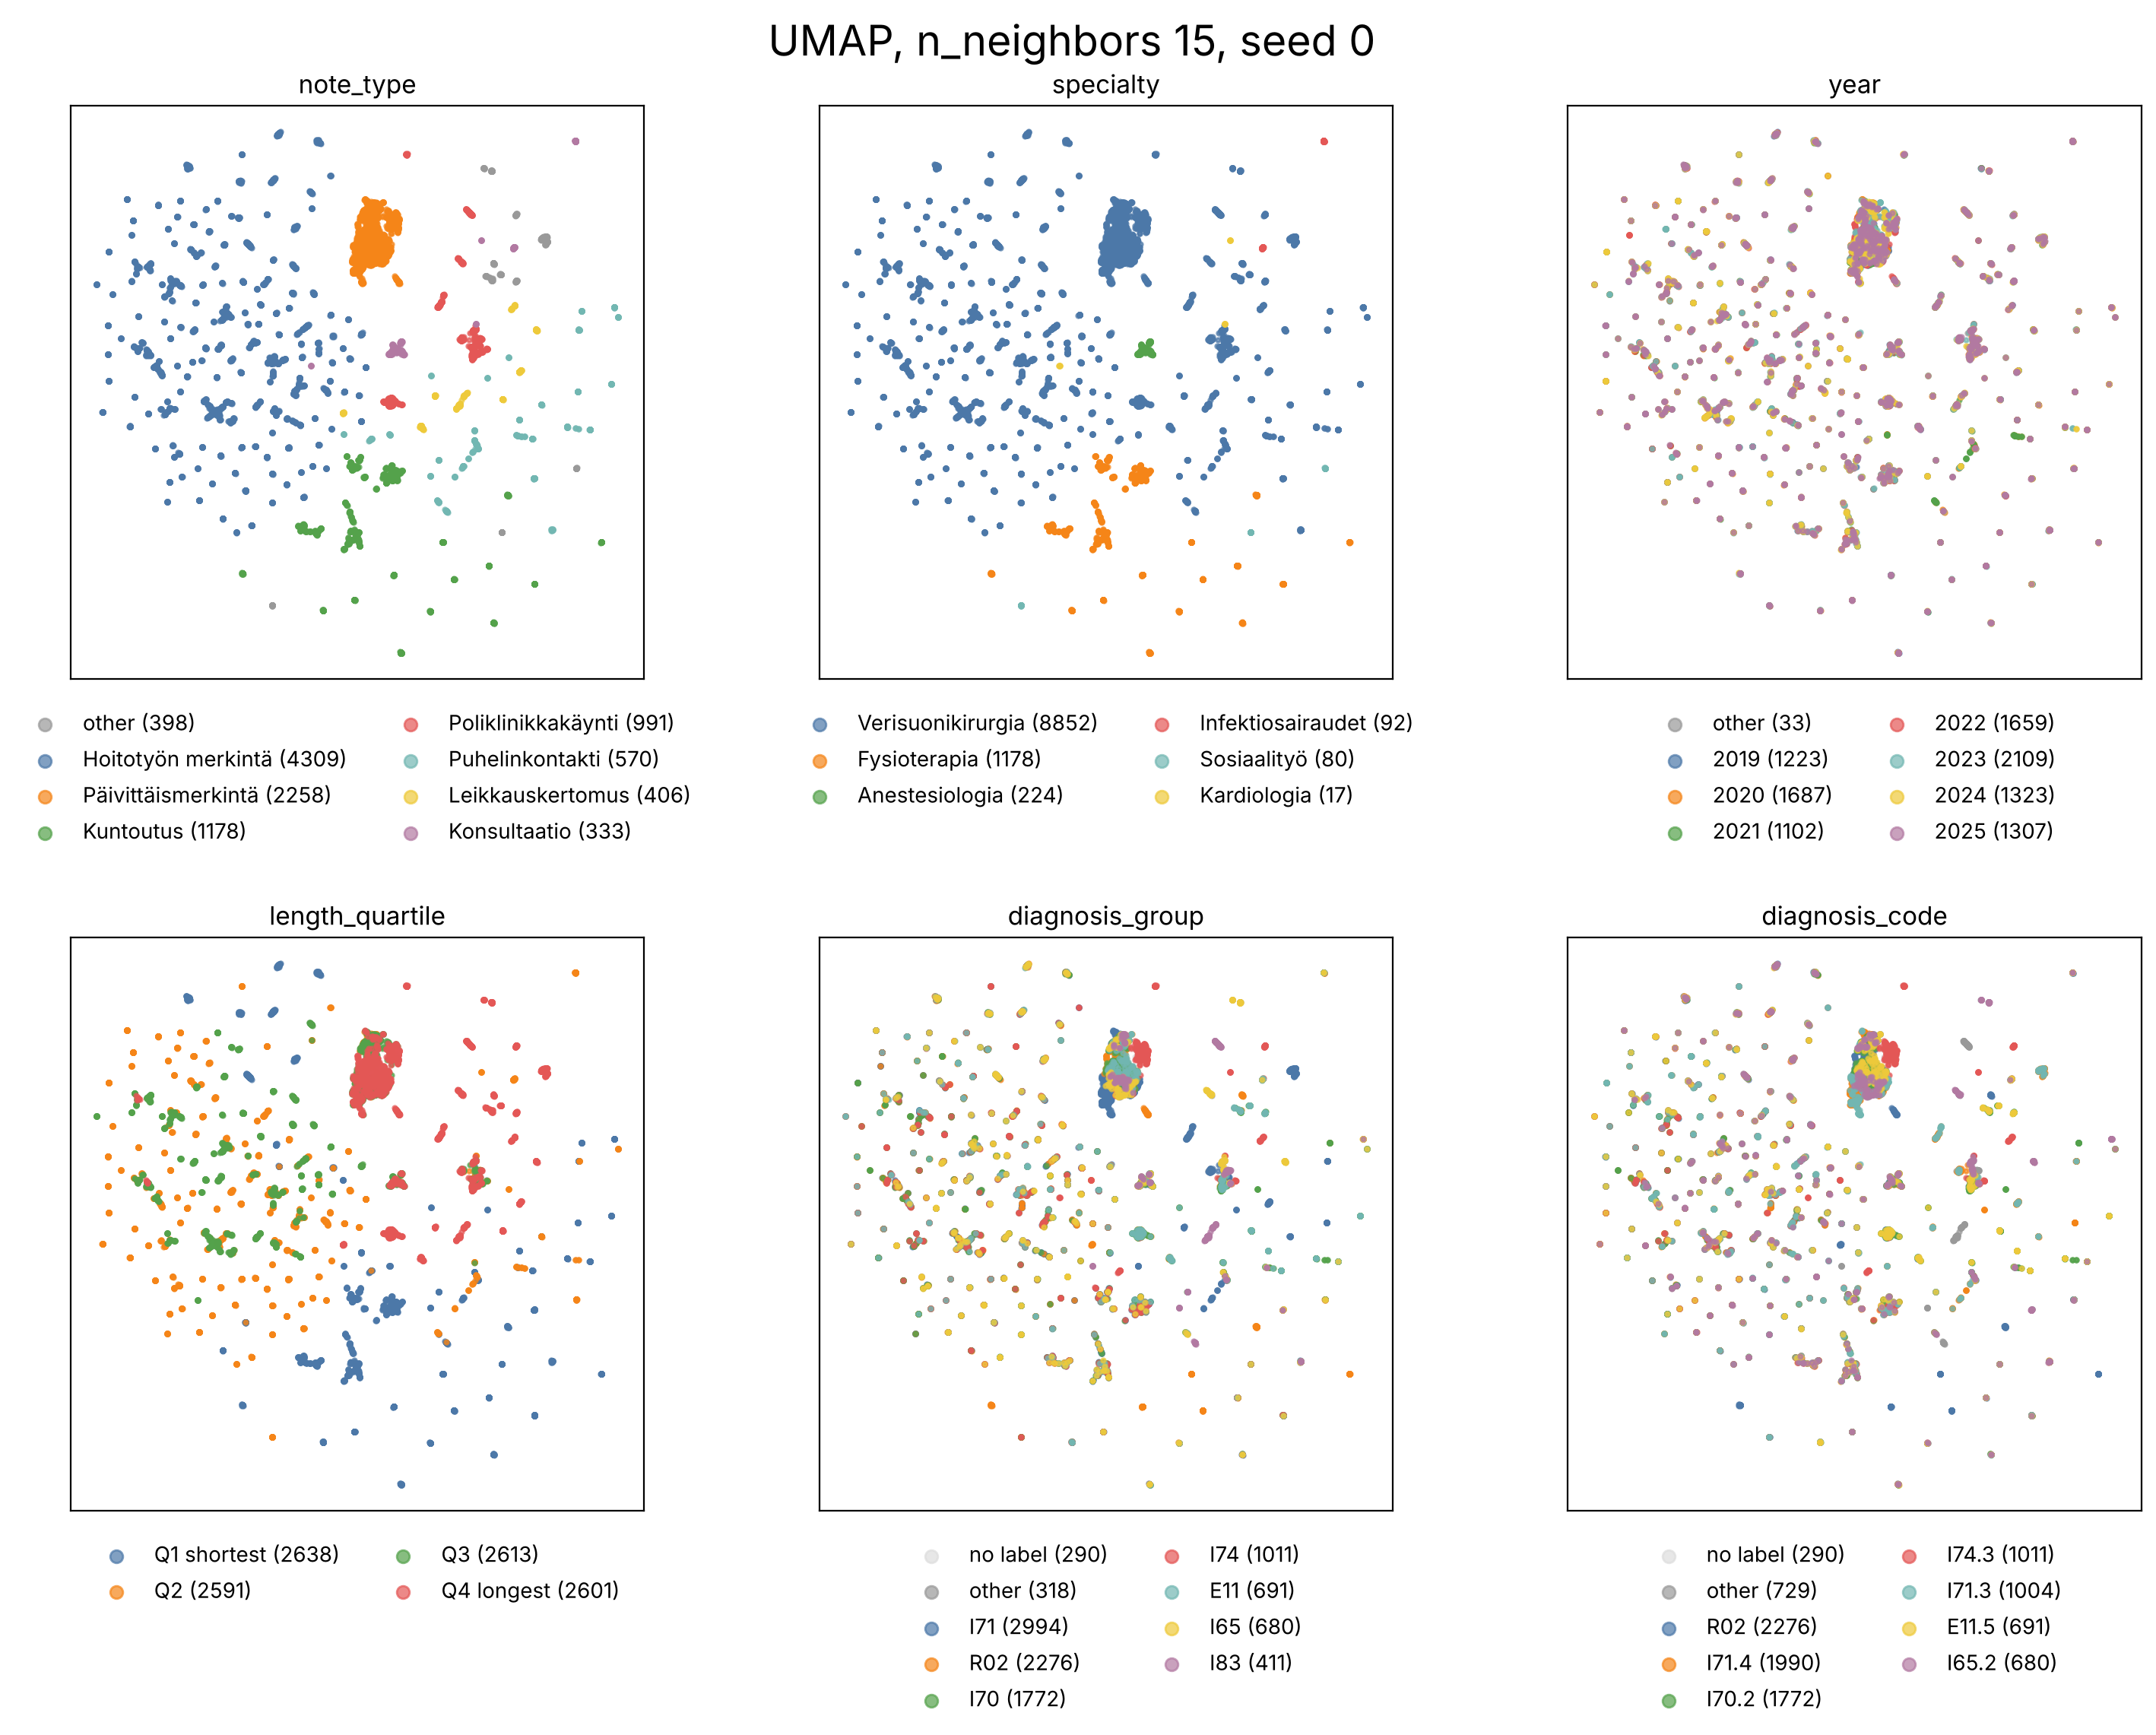

In [12]:
# UMAP, every setting with every seed
umap_points = {}
for n_neighbors in umap_neighbours:
    for projection_seed in seeds:
        reducer = umap.UMAP(n_neighbors=n_neighbors, min_dist=0.1, metric="cosine", init="pca", random_state=projection_seed, n_jobs=1) # One thread, because we fixed the seed
        umap_points[(n_neighbors, projection_seed)] = reducer.fit_transform(embeddings)
    print("UMAP n_neighbors %d done"
          % n_neighbors)
main_umap = umap_points[(15, 0)] # The main picture

# One picture per label
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.subplots_adjust(hspace=0.45) # Room for the legends between the rows
for index in range(len(labels_to_check)):
    label = labels_to_check[index]
    plot_by_label(axes.flat[index], main_umap, notes[label], label, label)
fig.suptitle("UMAP, n_neighbors 15, seed 0", y=0.93, fontsize=20)
fig.savefig(results_folder + "/umap.png", dpi=150, bbox_inches="tight")
plt.show()

# The coordinates of the main pictures, one row per note, so they are only saved on the synthetic data
if data_source == "synthetic":
    coordinates = pd.DataFrame({"note_id": notes["note_id"],
                                "pca_x": pca_points[:, 0], "pca_y": pca_points[:, 1],
                                "tsne_x": tsne_points[0][:, 0], "tsne_y": tsne_points[0][:, 1],
                                "umap_x": main_umap[:, 0], "umap_y": main_umap[:, 1]})
    coordinates.to_csv(results_folder + "/coordinates.csv", index=False)

### 5.4. Notes vs imaging texts <a class="anchor" id="section_5_4"></a>

The same picture as Rami's lung imaging figure, but inside one EHR: patient record notes, imaging reports and imaging requests embedded with the same model, in his colours. We took 2500 random notes, so that the notes did not swamp the imaging texts.

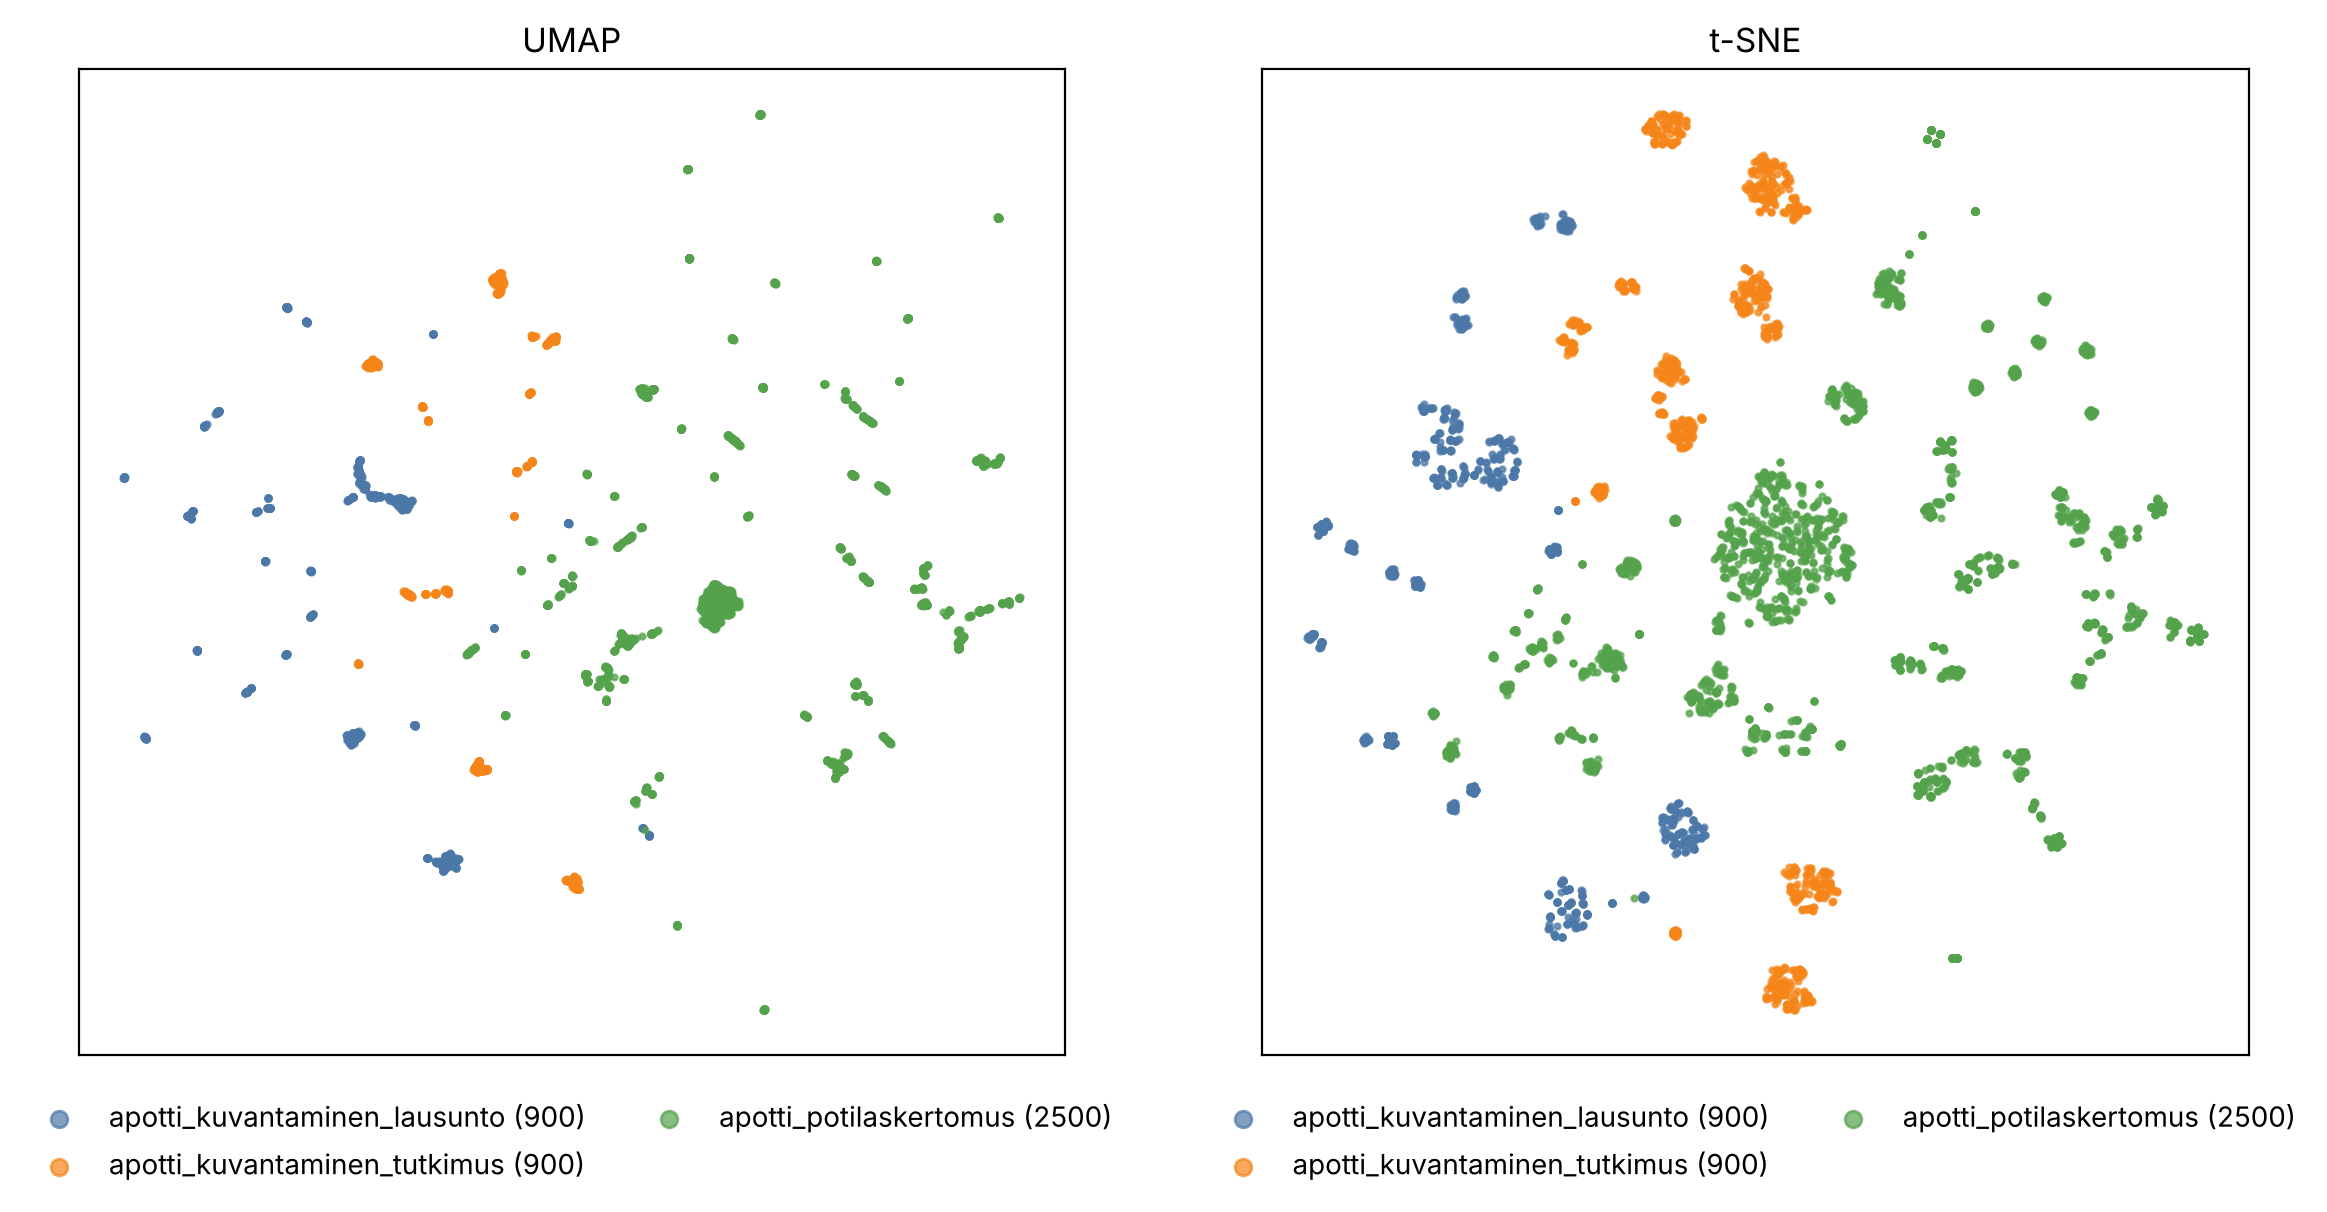

In [13]:
# 2500 random notes and the imaging texts together
note_sample = notes.sample(n=min(texts_per_table, notes.shape[0]), random_state=seed)
source_embeddings = np.vstack([embeddings[note_sample.index], imaging_embeddings])
source_labels = ["apotti_potilaskertomus"] * note_sample.shape[0] + imaging["source"].tolist()
source_patients = note_sample["patient_id"].tolist() + imaging["patient_id"].tolist()

# UMAP and t-SNE with the main settings
source_umap = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", init="pca", random_state=0, n_jobs=1).fit_transform(source_embeddings)
source_tsne = TSNE(metric="cosine", perplexity=30, init="pca", random_state=0).fit_transform(source_embeddings)

# Side by side, like Rami's figure
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
plot_by_label(axes[0], source_umap, source_labels, "source", "UMAP")
plot_by_label(axes[1], source_tsne, source_labels, "source", "t-SNE")
fig.savefig(results_folder + "/notes_vs_imaging.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Q1: Do the notes separate by text type? <a class="anchor" id="section_6"></a>

A picture can show clusters that are not really there, or hide ones that are. So next we wanted to check each picture with numbers, and we did it in the full 1024-number space as well as in 2-D.

**kNN label agreement.** For every note we looked at its 15 nearest notes and counted how many had the same label. We skipped notes from the same patient: copy-paste makes a patient's notes almost identical, and that would make every patient-level label, like the diagnosis, look separated. Big classes agree a lot just by chance, so we compared the agreement with the chance level, the sum of the squared class shares.

If the agreement is about the same in 2-D as in the full space, the picture is honest. If it is much lower, the picture hides structure.

In [14]:
def knn_agreement(points, labels, patients, metric):
    """For every note, the share of its k nearest notes from other patients that have the same label."""
    # Notes without a label (rare ICD codes) were left out
    has_label = pd.Series(list(labels)).notnull().to_numpy()
    points = points[has_label]
    labels = np.array(list(labels), dtype=object)[has_label]
    patients = np.array(list(patients))[has_label]

    # We asked for extra neighbours, because the same patient's notes are skipped
    number_of_neighbours = min(len(labels), k + most_notes_per_patient)
    nearest = NearestNeighbors(n_neighbors=number_of_neighbours, metric=metric)
    nearest.fit(points)
    distances, neighbours = nearest.kneighbors(points)

    agreement = np.zeros(len(labels))
    for n in range(len(labels)):
        other_patients = neighbours[n][patients[neighbours[n]] != patients[n]] # Skips the note itself and its patient
        agreement[n] = np.mean(labels[other_patients[:k]] == labels[n])
    return agreement, labels


def chance_level(labels):
    """Agreement we would get by chance: the sum of the squared class shares."""
    shares = pd.Series(labels).value_counts(normalize=True)
    return np.sum(shares ** 2)

In [15]:
# Agreement for every label, in the full space and in the three main pictures
rows = []
for label in labels_to_check:
    agreement_full, used_labels = knn_agreement(embeddings, notes[label], notes["patient_id"], "cosine")
    agreement_pca, used_labels = knn_agreement(pca_points, notes[label], notes["patient_id"], "euclidean")
    agreement_tsne, used_labels = knn_agreement(tsne_points[0], notes[label], notes["patient_id"], "euclidean")
    agreement_umap, used_labels = knn_agreement(main_umap, notes[label], notes["patient_id"], "euclidean")
    rows.append([label, chance_level(used_labels), np.mean(agreement_full),
                 np.mean(agreement_pca), np.mean(agreement_tsne), np.mean(agreement_umap)])

knn_table = pd.DataFrame(rows, columns=["label", "chance", "full", "pca", "tsne", "umap"])
knn_table.to_csv(results_folder + "/knn_agreement.csv", index=False)
knn_table.round(2)

,label,chance,full,pca,tsne,umap
0,note_type,0.25,1.00,0.85,1.00,1.00
1,specialty,0.73,1.00,0.96,1.00,1.00
2,year,0.15,0.15,0.15,0.15,0.15
3,length_quartile,0.25,0.84,0.68,0.84,0.82
4,diagnosis_group,0.19,0.42,0.25,0.42,0.41
5,diagnosis_code,0.15,0.34,0.20,0.34,0.32


In the synthetic data we wrote each note type in its own style on purpose. So if the pipeline works, note type should come out far above chance here, both in the full space and in the pictures.

Then the same check for the notes vs imaging texts from 5.4.

In [16]:
# Agreement for the text source, full space and the two pictures
agreement_full, used_labels = knn_agreement(source_embeddings, source_labels, source_patients, "cosine")
agreement_umap, used_labels = knn_agreement(source_umap, source_labels, source_patients, "euclidean")
agreement_tsne, used_labels = knn_agreement(source_tsne, source_labels, source_patients, "euclidean")
print("Notes vs imaging texts, chance %.2f: full space %.2f, UMAP %.2f, t-SNE %.2f"
      % (chance_level(used_labels), np.mean(agreement_full), np.mean(agreement_umap), np.mean(agreement_tsne)))

Notes vs imaging texts, chance 0.43: full space 1.00, UMAP 1.00, t-SNE 1.00


We also computed silhouette scores, as planned in the proposal. They go from -1 to 1, and around 0 means the classes overlap. Unlike the kNN agreement, they do not skip the same patient's notes.

In [17]:
# Silhouette for every label, full space and the three main pictures
rows = []
for label in labels_to_check:
    has_label = notes[label].notnull().to_numpy()
    labels = notes[label][has_label]
    rows.append([label,
                 silhouette_score(embeddings[has_label], labels, metric="cosine"),
                 silhouette_score(pca_points[has_label], labels),
                 silhouette_score(tsne_points[0][has_label], labels),
                 silhouette_score(main_umap[has_label], labels)])

silhouette_table = pd.DataFrame(rows, columns=["label", "full", "pca", "tsne", "umap"])
silhouette_table.to_csv(results_folder + "/silhouette.csv", index=False)
silhouette_table.round(2)

,label,full,pca,tsne,umap
0,note_type,0.33,0.38,0.18,0.27
1,specialty,0.17,-0.08,-0.13,-0.14
2,year,-0.03,-0.30,-0.21,-0.17
3,length_quartile,0.05,0.05,0.02,-0.00
4,diagnosis_group,-0.02,-0.28,-0.16,-0.15
5,diagnosis_code,-0.04,-0.30,-0.18,-0.17


## 7. Classifiers <a class="anchor" id="section_7"></a>

The episode's main diagnosis was predicted from each record. A linear classifier and a multilayer perceptron (MLP) with one hidden layer were applied to the full embeddings. Two linear baselines used note length and term frequency-inverse document frequency (TF-IDF). All four models were evaluated using the same five test folds grouped by patients.

Within each outer training fold, we considered five patient-grouped splits. A split was eligible if the fit set contained every diagnosis in the outer training fold and the validation set contained at least two diagnoses. For each eligible split, we counted distinct validation patients for every diagnosis in the outer training fold, counting a missing diagnosis as zero. We chose the split with the highest minimum count and kept the first split in a tie.

Training used full batches, so one epoch was one Adam step on all training notes. We scored seven checkpoints for the embedding and TF-IDF models and eleven for the length model. At each listed checkpoint, we calculated one-vs-rest AUROC (area under the receiver operating characteristic curve) for each diagnosis with both positive and negative validation notes. We gave each eligible diagnosis equal weight and selected the earliest checkpoint with the highest mean AUROC.

We saved the fit and validation cross-entropy, validation mean AUROC, and number of scored diagnoses at every checkpoint for every outer fold in `classifier_checkpoints.csv`. We show fold 1 below as a worked example.

We then refitted preprocessing and trained a new classifier on the full training fold for the selected number of epochs. On those training notes, we compared each model's cross-entropy with the loss of a predictor that used only the fold's diagnosis frequencies. We used the refitted classifier to predict diagnoses for the held-out test patients.

For each diagnosis, we pooled the held-out predictions from all five test folds and calculated one-vs-rest AUROC at the note level. This measures how often a note with that diagnosis receives a higher predicted probability for it than a note without it, counting ties as half. The two notes can come from different folds and be scored by different fitted models. We gave each diagnosis equal weight in the reported mean AUROC.

Nurses' and physiotherapists' notes say less about the diagnosis than doctors' notes, so we also report AUROC on doctors' notes alone, as planned in `mock_data/README.md`. The real notes had no role in them, so a note counted as a doctor's note by its type: Päivittäismerkintä, Leikkauskertomus or the anaesthesia pre-procedure assessment. We used the same held-out predictions and left out the other notes only when we calculated AUROC. The models and their epochs were still chosen with all notes.

In [18]:
# Notes with a diagnosis code, the rare codes were already left out in Section 3
has_code = notes["diagnosis_code"].notnull().to_numpy()
classes = sorted(notes["diagnosis_code"][has_code].unique())
y = notes["diagnosis_code"][has_code].map({code: i for i, code in enumerate(classes)}).to_numpy()
groups = notes["patient_id"][has_code].to_numpy()

# The same folds for every model, grouped by patient and stratified by code
folds = list(StratifiedGroupKFold(n_splits=number_of_folds, shuffle=True, random_state=seed).split(np.zeros(len(y)), y, groups))

print("Notes: %d, patients: %d, ICD codes: %d"
      % (len(y), len(set(groups)), len(classes)))

# fit_local and val_local are positions in train. Each entry in train is a row number in the classifier data.
splits = []
validation_patients = {}
for fold, (train, test) in enumerate(folds, start=1):
    splitter = StratifiedGroupKFold(n_splits=number_of_folds, shuffle=True, random_state=seed + 1)
    train_codes = np.unique(y[train])
    coverage = []
    best_split = None
    best_minimum = -1  # Zero is possible when every eligible split lacks a diagnosis.
    for fit_local, val_local in splitter.split(train, y[train], groups[train]):
        fit, val = train[fit_local], train[val_local]
        fit_codes, val_codes = len(np.unique(y[fit])), len(np.unique(y[val]))
        if fit_codes != len(train_codes) or val_codes < 2:
            coverage.append((fit_codes, val_codes))
            continue
        patients = np.array([len(np.unique(groups[val][y[val] == code])) for code in range(len(classes))])
        minimum = patients[train_codes].min()
        if minimum > best_minimum:
            best_minimum = minimum
            best_split = (fit, val, train, test)
            validation_patients[fold] = patients
    if best_split is None:
        raise ValueError(f"Outer fold {fold} needs all {len(train_codes)} training diagnoses in fit and "
                         f"at least two in validation. Diagnosis counts (fit, validation) per candidate: {coverage}")
    splits.append(best_split)

# Only how many codes had fewer than 3 validation patients, the counts themselves are too small to show
validation_table = pd.DataFrame(validation_patients, index=classes)
validation_table.index.name = "code"
print("ICD codes with fewer than %d validation patients, per outer fold (of %d codes)"
      % (minimum_count, len(classes)))
print((validation_table < minimum_count).sum().to_string())

Notes: 10153, patients: 579, ICD codes: 12


ICD codes with fewer than 3 validation patients, per outer fold (of 12 codes)
1    0
2    1
3    0
4    0
5    0


In [19]:
def prepare_features(features, train, held_out, *, tfidf=False):
    """Fit the vocabulary (for text) and scaler using only this training split."""
    X_train, X_held_out = features[train], features[held_out]
    if tfidf:
        vectorizer = TfidfVectorizer(max_features=tfidf_words, dtype=np.float32)
        X_train = vectorizer.fit_transform(X_train).toarray()
        X_held_out = vectorizer.transform(X_held_out).toarray()

    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0)
    std[std == 0] = 1
    return (torch.as_tensor((X_train - mean) / std, dtype=torch.float32, device=device),
            torch.as_tensor((X_held_out - mean) / std, dtype=torch.float32, device=device))


def train_checkpoints(X_train, targets, checkpoints, hidden=None):
    """Train once, yielding the current model after each requested epoch."""
    torch.manual_seed(seed)
    if hidden is None:
        model = nn.Linear(X_train.shape[1], len(classes))
    else:
        model = nn.Sequential(nn.Linear(X_train.shape[1], hidden), nn.ReLU(), nn.Linear(hidden, len(classes)))
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    previous_epoch = 0
    for epoch in checkpoints:
        model.train()
        for _ in range(previous_epoch, epoch):
            optimizer.zero_grad()
            loss = nn.functional.cross_entropy(model(X_train), targets)
            loss.backward()
            optimizer.step()
        model.eval()
        yield epoch, model
        previous_epoch = epoch


def select_epoch(X_fit, fit_targets, X_val, val_labels, checkpoints, hidden):
    """Score validation checkpoints and select the earliest with the highest macro AUROC."""
    counts = np.bincount(val_labels, minlength=len(classes))
    codes = np.flatnonzero((counts > 0) & (counts < len(val_labels))) # At least two, because of the split rule
    val_targets = torch.as_tensor(val_labels, device=device)
    rows = []
    for epoch, model in train_checkpoints(X_fit, fit_targets, checkpoints, hidden):
        with torch.no_grad():
            fit_loss = nn.functional.cross_entropy(model(X_fit), fit_targets).item()
            logits = model(X_val)
            val_loss = nn.functional.cross_entropy(logits, val_targets).item()
            scores = logits.softmax(dim=1).cpu().numpy()
        auc = np.mean([roc_auc_score(val_labels == code, scores[:, code]) for code in codes])
        rows.append((epoch, fit_loss, val_loss, auc, len(codes)))
    history = pd.DataFrame(rows, columns=["epoch", "fit_loss", "validation_loss", "macro_auroc", "codes"])
    return int(history.loc[history["macro_auroc"].idxmax(), "epoch"]), history

In [20]:
def cross_validate(name, features, checkpoints, *, hidden=None, tfidf=False):
    """Return test predictions, selected epochs, refit losses and checkpoint histories for all folds."""
    predictions = np.empty((len(y), len(classes)))
    selected = []
    refit_losses = []
    histories = []
    for fold, (fit, val, train, test) in enumerate(splits, start=1):
        X_fit, X_val = prepare_features(features, fit, val, tfidf=tfidf)
        epoch, history = select_epoch(X_fit, torch.as_tensor(y[fit], device=device),
                                      X_val, y[val], checkpoints, hidden)
        selected.append(epoch)
        histories.append(history.assign(model=name, fold=fold))
        if fold == 1:
            print(name, "on validation fold 1")
            print(history.round(4).to_string(index=False))
        del X_fit, X_val

        X_train, X_test = prepare_features(features, train, test, tfidf=tfidf)
        targets = torch.as_tensor(y[train], device=device)
        for _, model in train_checkpoints(X_train, targets, [epoch], hidden):
            with torch.no_grad():
                refit_losses.append(nn.functional.cross_entropy(model(X_train), targets).item())
                predictions[test] = model(X_test).softmax(dim=1).cpu().numpy()
        del X_train, X_test
    return predictions, selected, refit_losses, histories


lengths = np.log(notes.loc[has_code, ["characters", "tokens"]].to_numpy())
texts = notes.loc[has_code, "text"].to_numpy()
embedding_features = embeddings[has_code]
probabilities = {}
selected_epochs = {}
checkpoint_histories = []
# Entropy of the training counts is the loss from predicting those same frequencies for every note.
training_losses = {"Class frequency": [stats.entropy(np.bincount(y[train])) for train, _ in folds]}
for name, features, checkpoints, options in [
    ("Embeddings, linear", embedding_features, checkpoint_epochs, {}),
    ("Embeddings, MLP", embedding_features, checkpoint_epochs, {"hidden": hidden_units}),
    ("Length", lengths, length_checkpoints, {}),
    ("TF-IDF", texts, checkpoint_epochs, {"tfidf": True}),
]:
    predictions, epochs, losses, histories = cross_validate(name, features, checkpoints, **options)
    probabilities[name] = predictions
    selected_epochs[name] = epochs
    training_losses[name] = losses
    checkpoint_histories.extend(histories)

pd.concat(checkpoint_histories, ignore_index=True).to_csv(
    results_folder + "/classifier_checkpoints.csv", index=False,
    columns=["model", "fold", "epoch", "fit_loss", "validation_loss", "macro_auroc", "codes"])

fold_index = pd.Index(range(1, len(splits) + 1), name="fold")
print("Selected epoch by outer fold")
print(pd.DataFrame(selected_epochs, index=fold_index))
print("Training cross-entropy after refitting each outer fold")
print(pd.DataFrame(training_losses, index=fold_index).round(4).to_string())

Embeddings, linear on validation fold 1
 epoch  fit_loss  validation_loss  macro_auroc  codes
    10    1.8966           2.0096       0.7620     12
    25    1.5678           1.7448       0.8166     12
    50    1.3683           1.6063       0.8294     12
   100    1.2248           1.5128       0.8289     12
   200    1.1074           1.4677       0.8198     12
   500    0.9787           1.5120       0.8109     12
  1000    0.8881           1.6175       0.8045     12


Embeddings, MLP on validation fold 1
 epoch  fit_loss  validation_loss  macro_auroc  codes
    10    1.3912           1.5242       0.8244     12
    25    1.1630           1.3883       0.8542     12
    50    1.0115           1.3878       0.8740     12
   100    0.7937           1.5411       0.8671     12
   200    0.5324           1.9411       0.8541     12
   500    0.2669           2.9016       0.8305     12
  1000    0.1812           3.7160       0.8215     12


Length on validation fold 1
 epoch  fit_loss  validation_loss  macro_auroc  codes
    10    2.7750           2.7745       0.4676     12
    25    2.7540           2.7532       0.4660     12
    50    2.7212           2.7197       0.4694     12
   100    2.6634           2.6607       0.4967     12
   200    2.5705           2.5662       0.5106     12
   500    2.3822           2.3770       0.5411     12
  1000    2.2137           2.2075       0.5507     12
  2000    2.1041           2.0961       0.5588     12
  5000    2.0649           2.0571       0.5871     12
 10000    2.0621           2.0544       0.5893     12
 20000    2.0621           2.0544       0.5893     12


TF-IDF on validation fold 1
 epoch  fit_loss  validation_loss  macro_auroc  codes
    10    1.8005           1.9877       0.7789     12
    25    1.3566           1.6855       0.8026     12
    50    1.1335           1.5726       0.8262     12
   100    1.0227           1.5679       0.8230     12
   200    0.9666           1.6243       0.8227     12
   500    0.9308           1.7582       0.8135     12
  1000    0.9177           1.8962       0.8040     12


Selected epoch by outer fold
      Embeddings, linear  Embeddings, MLP  Length  TF-IDF
fold                                                     
1                     50               50   20000      50
2                    100               50   20000     200
3                    100               50    5000      25
4                    200               50   20000      50
5                    500               50   10000      50
Training cross-entropy after refitting each outer fold
      Class frequency  Embeddings, linear  Embeddings, MLP  Length  TF-IDF
fold                                                                      
1              2.0756              1.3907           1.0515  2.0603  1.1655
2              2.0728              1.2576           1.0561  2.0562  1.0110
3              2.0738              1.2666           1.0623  2.0635  1.4012
4              2.0717              1.1495           1.0678  2.0572  1.1811
5              2.0730              1.0321           1.0619  

In [21]:
def auroc_table(subset):
    """One-vs-rest AUROC per ICD code and model at note level, using only the notes in subset."""
    rows = []
    for index in range(len(classes)):
        is_code = y[subset] == index
        patients = len(np.unique(groups[subset][is_code])) # Patients with this code in the subset
        if patients < min_patients_per_code:
            rows.append([classes[index], np.nan] + [np.nan for model in probabilities]) # Too few patients to score or show
            continue
        rows.append([classes[index], patients] + [roc_auc_score(is_code, probabilities[model][subset, index]) for model in probabilities])
    return pd.DataFrame(rows, columns=["diagnosis_code", "patients"] + list(probabilities))


# The test folds of all five splits together, for all notes and for doctors' notes only
doctor = notes["doctor"][has_code].to_numpy()
classifier_table = auroc_table(np.full(len(y), True))
doctors_table = auroc_table(doctor)
classifier_table.to_csv(results_folder + "/classifier_auroc.csv", index=False)
doctors_table.to_csv(results_folder + "/classifier_auroc_doctors.csv", index=False)

# Section 8 uses the linear model on the embeddings, the main classifier, on all notes
auroc_per_code = classifier_table.rename(columns={"Embeddings, linear": "auroc"})[["diagnosis_code", "auroc"]]
auroc_per_code.to_csv(results_folder + "/classifier_auroc_per_code.csv", index=False)

# Codes with enough doctors' patients, so all notes can also be compared on the same codes
scored_in_doctors = doctors_table["Embeddings, linear"].notnull()
print("Doctors' notes: %d of %d"
      % (doctor.sum(), len(y)))
print("Codes scored: %d with all notes, %d with doctors' notes"
      % (classifier_table.shape[0], scored_in_doctors.sum()))
print("Mean AUROC over the codes")
print(pd.DataFrame({"All notes": classifier_table[list(probabilities)].mean(),
                    "All notes, same codes": classifier_table[scored_in_doctors][list(probabilities)].mean(),
                    "Doctors' notes": doctors_table[list(probabilities)].mean()}).round(3))

# Only the codes with enough doctors' patients, all notes and doctors' notes side by side. Every code is in the csv files
same_codes = doctors_table["diagnosis_code"][scored_in_doctors]
pd.concat({"All notes": classifier_table.set_index("diagnosis_code"),
           "Doctors' notes": doctors_table.set_index("diagnosis_code")}, axis=1).loc[same_codes].round(2)

Doctors' notes: 2603 of 10153
Codes scored: 12 with all notes, 11 with doctors' notes
Mean AUROC over the codes
                    All notes  All notes, same codes  Doctors' notes
Embeddings, linear      0.833                  0.853           0.959
Embeddings, MLP         0.866                  0.865           0.965
Length                  0.570                  0.566           0.524
TF-IDF                  0.814                  0.836           0.949


All notes                                                   \
                patients Embeddings, linear Embeddings, MLP Length TF-IDF   
diagnosis_code                                                              
E11.5                 56               0.75            0.76   0.51   0.73   
G45.9                 23               0.81            0.84   0.51   0.81   
I65.2                 58               0.85            0.87   0.49   0.82   
I70.2                142               0.79            0.79   0.50   0.76   
I71.3                 28               0.80            0.80   0.53   0.79   
I71.4                 99               0.83            0.84   0.52   0.82   
I74.3                 32               0.83            0.84   0.51   0.82   
I83.0                 32               0.98            0.99   0.73   0.98   
I83.1                 23               0.96            0.98   0.64   0.91   
I83.9                 51               0.99            0.99   0.70   0.98   
R02                   61               0.80            0.81   0.57   0.78   

               Doctors' notes                                                   
                     patients Embeddings, linear Embeddings, MLP Length TF-IDF  
diagnosis_code                                                                  
E11.5                    34.0               0.88            0.89   0.54   0.86  
G45.9                    13.0               0.97            0.97   0.49   0.95  
I65.2                    33.0               0.99            0.99   0.40   0.98  
I70.2                    70.0               0.91            0.92   0.45   0.88  
I71.3                    18.0               0.96            0.97   0.62   0.95  
I71.4                    61.0               0.98            0.98   0.61   0.97  
I74.3                    30.0               1.00            1.00   0.47   1.00  
I83.0                    28.0               0.99            0.99   0.65   0.98  
I83.1                    14.0               0.96            0.98   0.47   0.96  
I83.9                    46.0               0.99            0.99   0.53   0.99  
R02                      53.0               0.93            0.94   0.53   0.92

## 8. Q2: Does the picture predict how hard a diagnosis is? <a class="anchor" id="section_8"></a>

Following the feedback, we used the finer ICD-10 codes instead of the four groups, so that the rank correlation has more than four points.

For each code we measured how separated it looks in the main UMAP, and put that next to how well the classifier did on it (AUROC from Section 7). We used agreement above chance, where 0 means no better than chance and 1 means all 15 neighbours have the same code. The plain agreement goes up just because a code is common, so on its own it would not work for comparing codes.

If the codes line up, the picture works as a cheap check of how hard a diagnosis task will be. With 10 or more codes we report the Spearman correlation; with fewer we only describe it.

In [22]:
# Agreement per ICD code, full space and main UMAP
agreement_full, codes = knn_agreement(embeddings, notes["diagnosis_code"], notes["patient_id"], "cosine")
agreement_umap, codes = knn_agreement(main_umap, notes["diagnosis_code"], notes["patient_id"], "euclidean")

rows = []
for code in sorted(set(codes)):
    is_code = codes == code
    chance = np.mean(is_code) # Share of notes with this code
    full_score = (np.mean(agreement_full[is_code]) - chance) / (1 - chance) # Agreement above chance
    umap_score = (np.mean(agreement_umap[is_code]) - chance) / (1 - chance)
    patients = notes.loc[notes["diagnosis_code"] == code, "patient_id"].nunique()
    rows.append([code, patients, np.sum(is_code), full_score, umap_score])

code_table = pd.DataFrame(rows, columns=["diagnosis_code", "patients", "notes", "full", "umap"])

# Classifier AUROC per code from Section 7
code_table = code_table.merge(auroc_per_code, on="diagnosis_code", how="left")

code_table.to_csv(results_folder + "/per_code.csv", index=False)
code_table.sort_values("patients", ascending=False).head(10).round(2) # Ten most common codes here, every code is in per_code.csv

,diagnosis_code,patients,notes,full,umap,auroc
3,I70.2,142,1772,0.18,0.16,0.79
5,I71.4,99,1990,0.28,0.25,0.83
10,R02,61,2276,0.24,0.24,0.80
2,I65.2,58,680,0.27,0.23,0.85
0,E11.5,56,691,0.07,0.06,0.75
9,I83.9,51,197,0.40,0.31,0.99
7,I83.0,32,127,0.25,0.24,0.98
6,I74.3,32,1011,0.31,0.33,0.83
4,I71.3,28,1004,0.12,0.11,0.80
1,G45.9,23,282,0.07,0.08,0.81


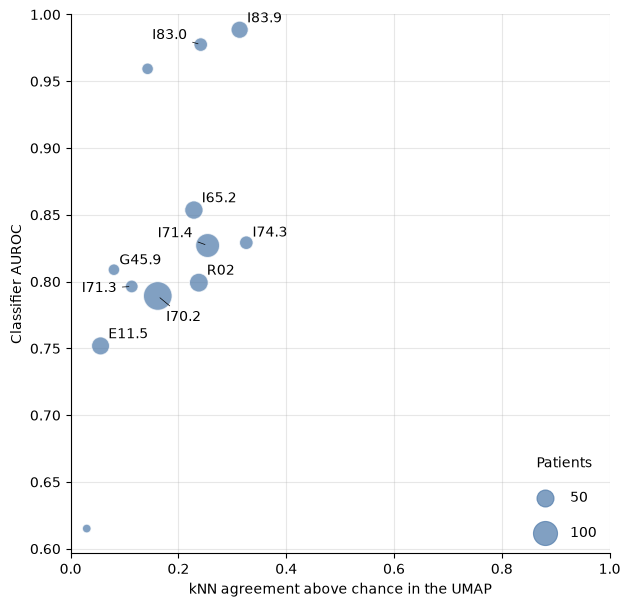

Spearman correlation 0.70, p = 0.0114, 12 codes


In [23]:
# Picture vs classifier, one dot per ICD code, dot size by the number of patients
fig, ax = plt.subplots(figsize=(7, 7))
dots = ax.scatter(code_table["umap"], code_table["auroc"], s=3 * code_table["patients"],
                  color=palette[0], alpha=0.7, edgecolor="white", linewidth=0.8,
                  clip_on=False) # White edge separates touching dots, dots at the edges are not cut) # White edge separates touching dots

# Labels for the ten most common codes, placed just outside the edge of the dot
label_shift = {"I70.2": (6, -18), "I71.4": (-36, 6), "I71.3": (-36, -4), "I83.0": (-35, 4)} # Labels moved by hand, in points (right, up)
for index in code_table.sort_values("patients", ascending=False).index[:10]:
    code = code_table["diagnosis_code"][index]
    radius = np.sqrt(3 * code_table["patients"][index]) / 2 # Dot radius in points
    if code in label_shift:
        ax.annotate(code, (code_table["umap"][index], code_table["auroc"][index]),
                    xytext=label_shift[code], textcoords="offset points",
                    arrowprops={"arrowstyle": "-", "linewidth": 0.5}) # Thin line to the dot
    else:
        ax.annotate(code, (code_table["umap"][index], code_table["auroc"][index]),
                    xytext=(0.7 * radius + 1, 0.7 * radius + 1), textcoords="offset points") # Up and right of the dot edge

# Legend for dot size, sizes turned back into numbers of patients
handles, labels = dots.legend_elements(prop="sizes", num=3, func=lambda size: size / 3,
                                       color=palette[0], alpha=0.7)
ax.legend(handles, labels, title="Patients", loc="lower right",
          frameon=False, labelspacing=1.5) # Extra spacing so the big dots do not overlap

# Axes
ax.set_xlabel("kNN agreement above chance in the UMAP")
ax.set_ylabel("Classifier AUROC")
ax.set_xlim(0, 1)
ax.set_ylim(top=1.0) # AUROC cannot go above 1
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
ax.set_axisbelow(True) # Grid behind the dots
ax.set_box_aspect(1)
fig.savefig(results_folder + "/picture_vs_classifier.png", dpi=300, bbox_inches="tight")
plt.show()

# Spearman correlation, only with 10 or more codes
if code_table.shape[0] >= 10:
    correlation, p_value = stats.spearmanr(code_table["umap"], code_table["auroc"])
    print("Spearman correlation %.2f, p = %.3g, %d codes"
          % (correlation, p_value, code_table.shape[0]))
else:
    print("Only %d codes, so we describe this instead of giving a correlation"
          % code_table.shape[0])

In [24]:
# Sensitivity checks for Q2: the MLP and TF-IDF instead of the linear model, and each code left out in turn
sensitivity = code_table[["diagnosis_code", "umap"]].merge(classifier_table, on="diagnosis_code")
for model in ["Embeddings, linear", "Embeddings, MLP", "TF-IDF"]:
    correlation, p_value = stats.spearmanr(sensitivity["umap"], sensitivity[model])

    # The correlation again, with one code left out at a time
    correlations_without_code = []
    for index in range(sensitivity.shape[0]):
        without_code = sensitivity.drop(index)
        correlation_without_code, _ = stats.spearmanr(without_code["umap"], without_code[model])
        correlations_without_code.append(correlation_without_code)

    print("%s: Spearman %.2f, p = %.3g, leaving one code out %.2f to %.2f"
          % (model, correlation, p_value, np.min(correlations_without_code), np.max(correlations_without_code)))

Embeddings, linear: Spearman 0.70, p = 0.0114, leaving one code out 0.61 to 0.80
Embeddings, MLP: Spearman 0.43, p = 0.159, leaving one code out 0.31 to 0.61
TF-IDF: Spearman 0.67, p = 0.0168, leaving one code out 0.57 to 0.77


## 9. Seeds and UMAP settings <a class="anchor" id="section_9"></a>

We did not want any conclusion to rest on one picture. So we repeated the kNN agreement for note type (Q1) and diagnosis code (Q2) over every t-SNE seed and every UMAP setting and seed, and compared them with PCA and the full space.

In [25]:
# Agreement in every t-SNE and UMAP run
rows = []
for label in ["note_type", "diagnosis_code"]:
    for projection_seed in seeds:
        agreement, used_labels = knn_agreement(tsne_points[projection_seed], notes[label], notes["patient_id"], "euclidean")
        rows.append([label, "t-SNE", projection_seed, np.mean(agreement)])
    for n_neighbors in umap_neighbours:
        for projection_seed in seeds:
            agreement, used_labels = knn_agreement(umap_points[(n_neighbors, projection_seed)], notes[label], notes["patient_id"], "euclidean")
            rows.append([label, "UMAP n_neighbors %d" % n_neighbors, projection_seed, np.mean(agreement)])

seed_table = pd.DataFrame(rows, columns=["label", "projection", "seed", "agreement"])
seed_table.to_csv(results_folder + "/seeds_and_settings.csv", index=False)

# Mean, lowest and highest over the five seeds
print(seed_table.groupby(["label", "projection"])["agreement"].agg(["mean", "min", "max"]).round(2))

# PCA and the full space for comparison, from Section 6
print()
print(knn_table[knn_table["label"].isin(["note_type", "diagnosis_code"])][["label", "chance", "full", "pca"]].round(2))

                                    mean   min   max
label          projection                           
diagnosis_code UMAP n_neighbors 15  0.33  0.32  0.33
               UMAP n_neighbors 5   0.31  0.31  0.32
               UMAP n_neighbors 50  0.32  0.32  0.32
               t-SNE                0.34  0.34  0.34
note_type      UMAP n_neighbors 15  1.00  1.00  1.00
               UMAP n_neighbors 5   0.98  0.97  0.98
               UMAP n_neighbors 50  1.00  1.00  1.00
               t-SNE                1.00  1.00  1.00

            label  chance  full   pca
0       note_type    0.25  1.00  0.85
5  diagnosis_code    0.15  0.34  0.20


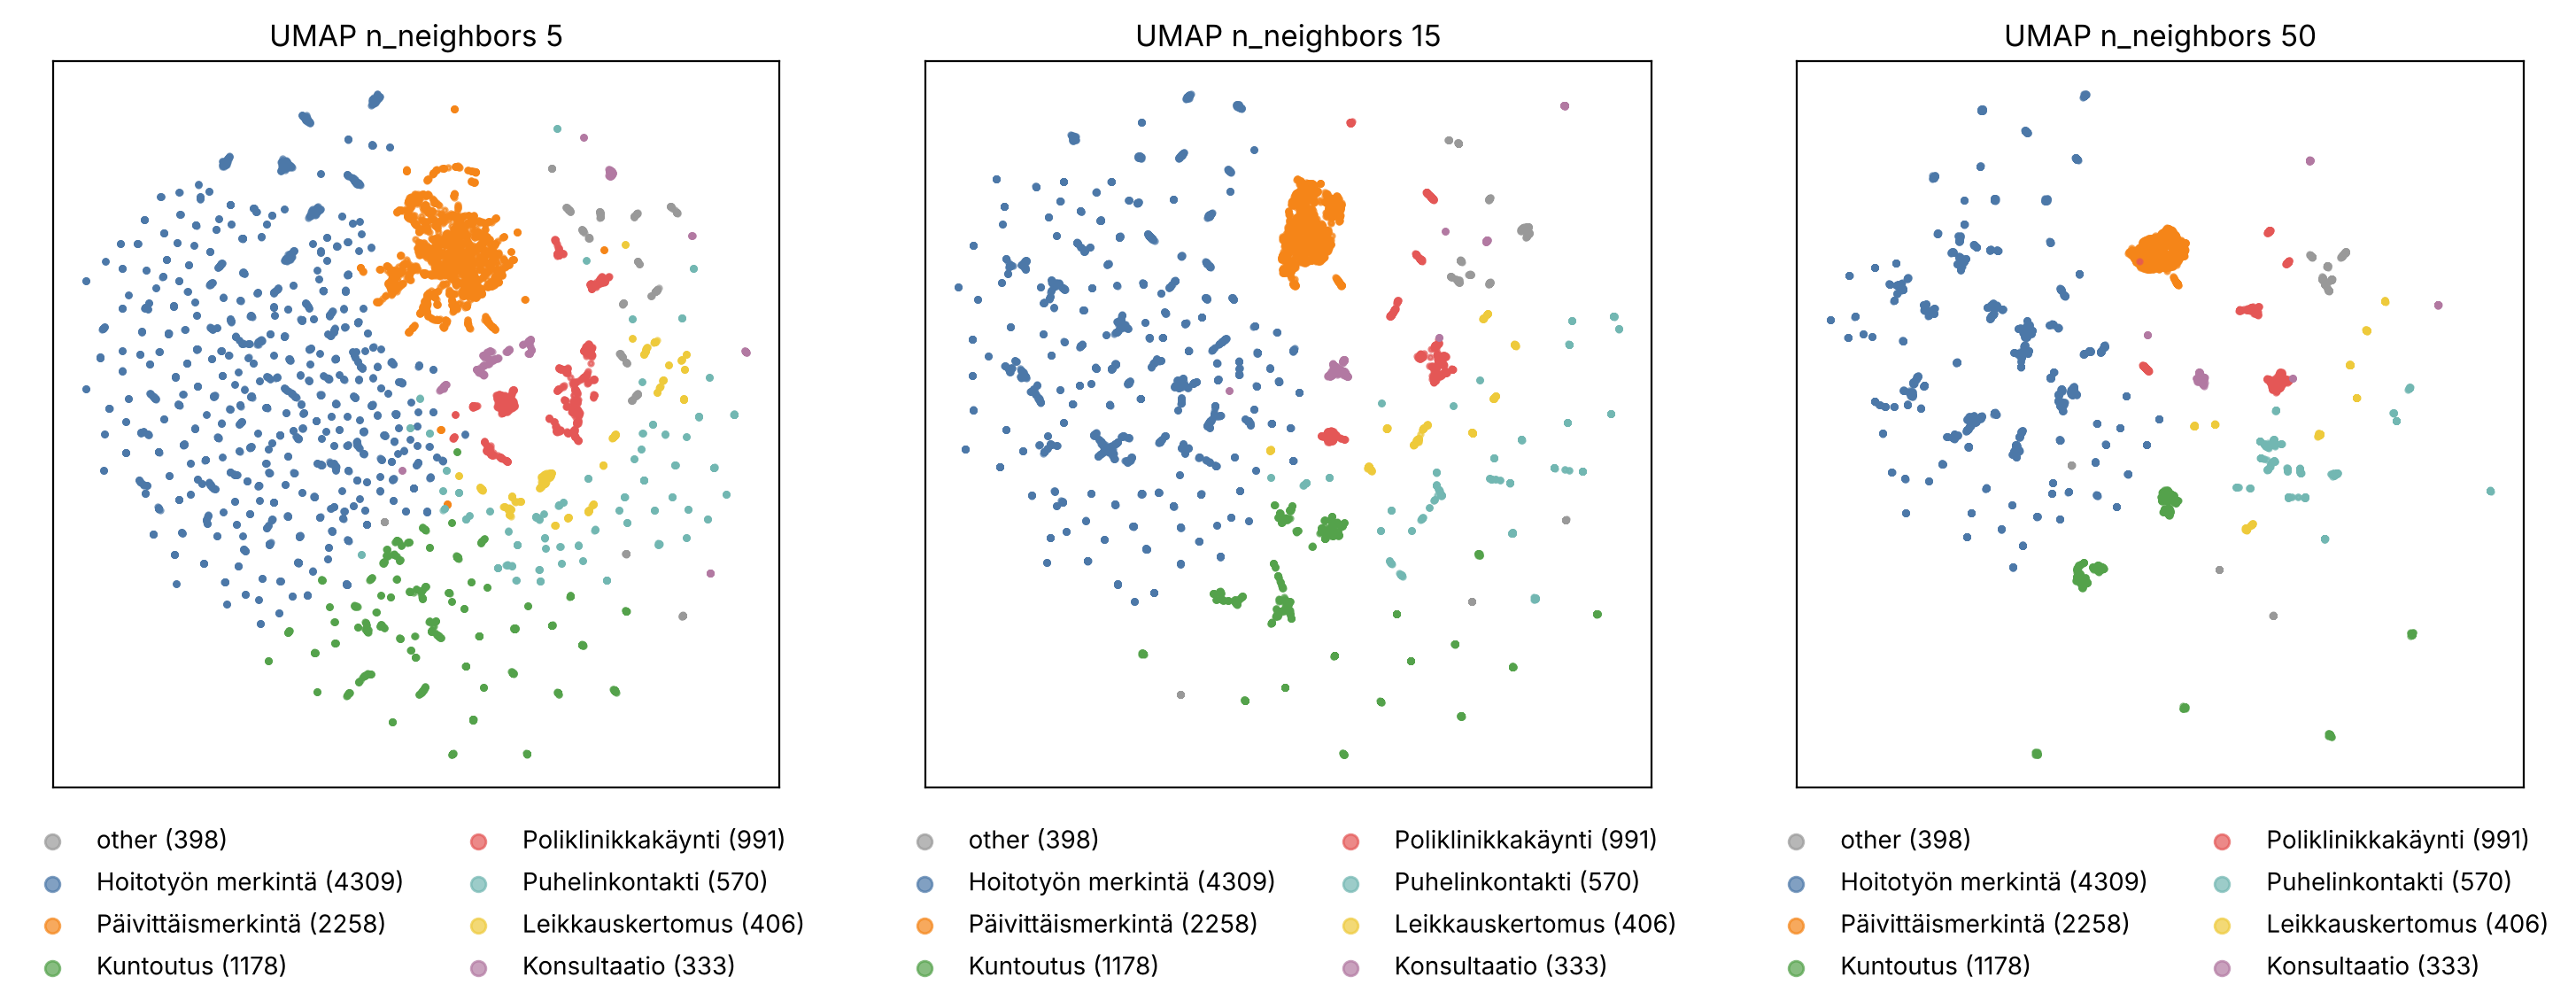

In [26]:
# The three UMAP settings side by side, coloured by note type
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for index in range(len(umap_neighbours)):
    n_neighbors = umap_neighbours[index]
    plot_by_label(axes[index], umap_points[(n_neighbors, 0)], notes["note_type"], "note_type", "UMAP n_neighbors %d" % n_neighbors)
fig.savefig(results_folder + "/umap_settings.png", dpi=150, bbox_inches="tight")
plt.show()

note_type: 1.00 in the original order, 1.00 shuffled


diagnosis_code: 0.32 in the original order, 0.32 shuffled


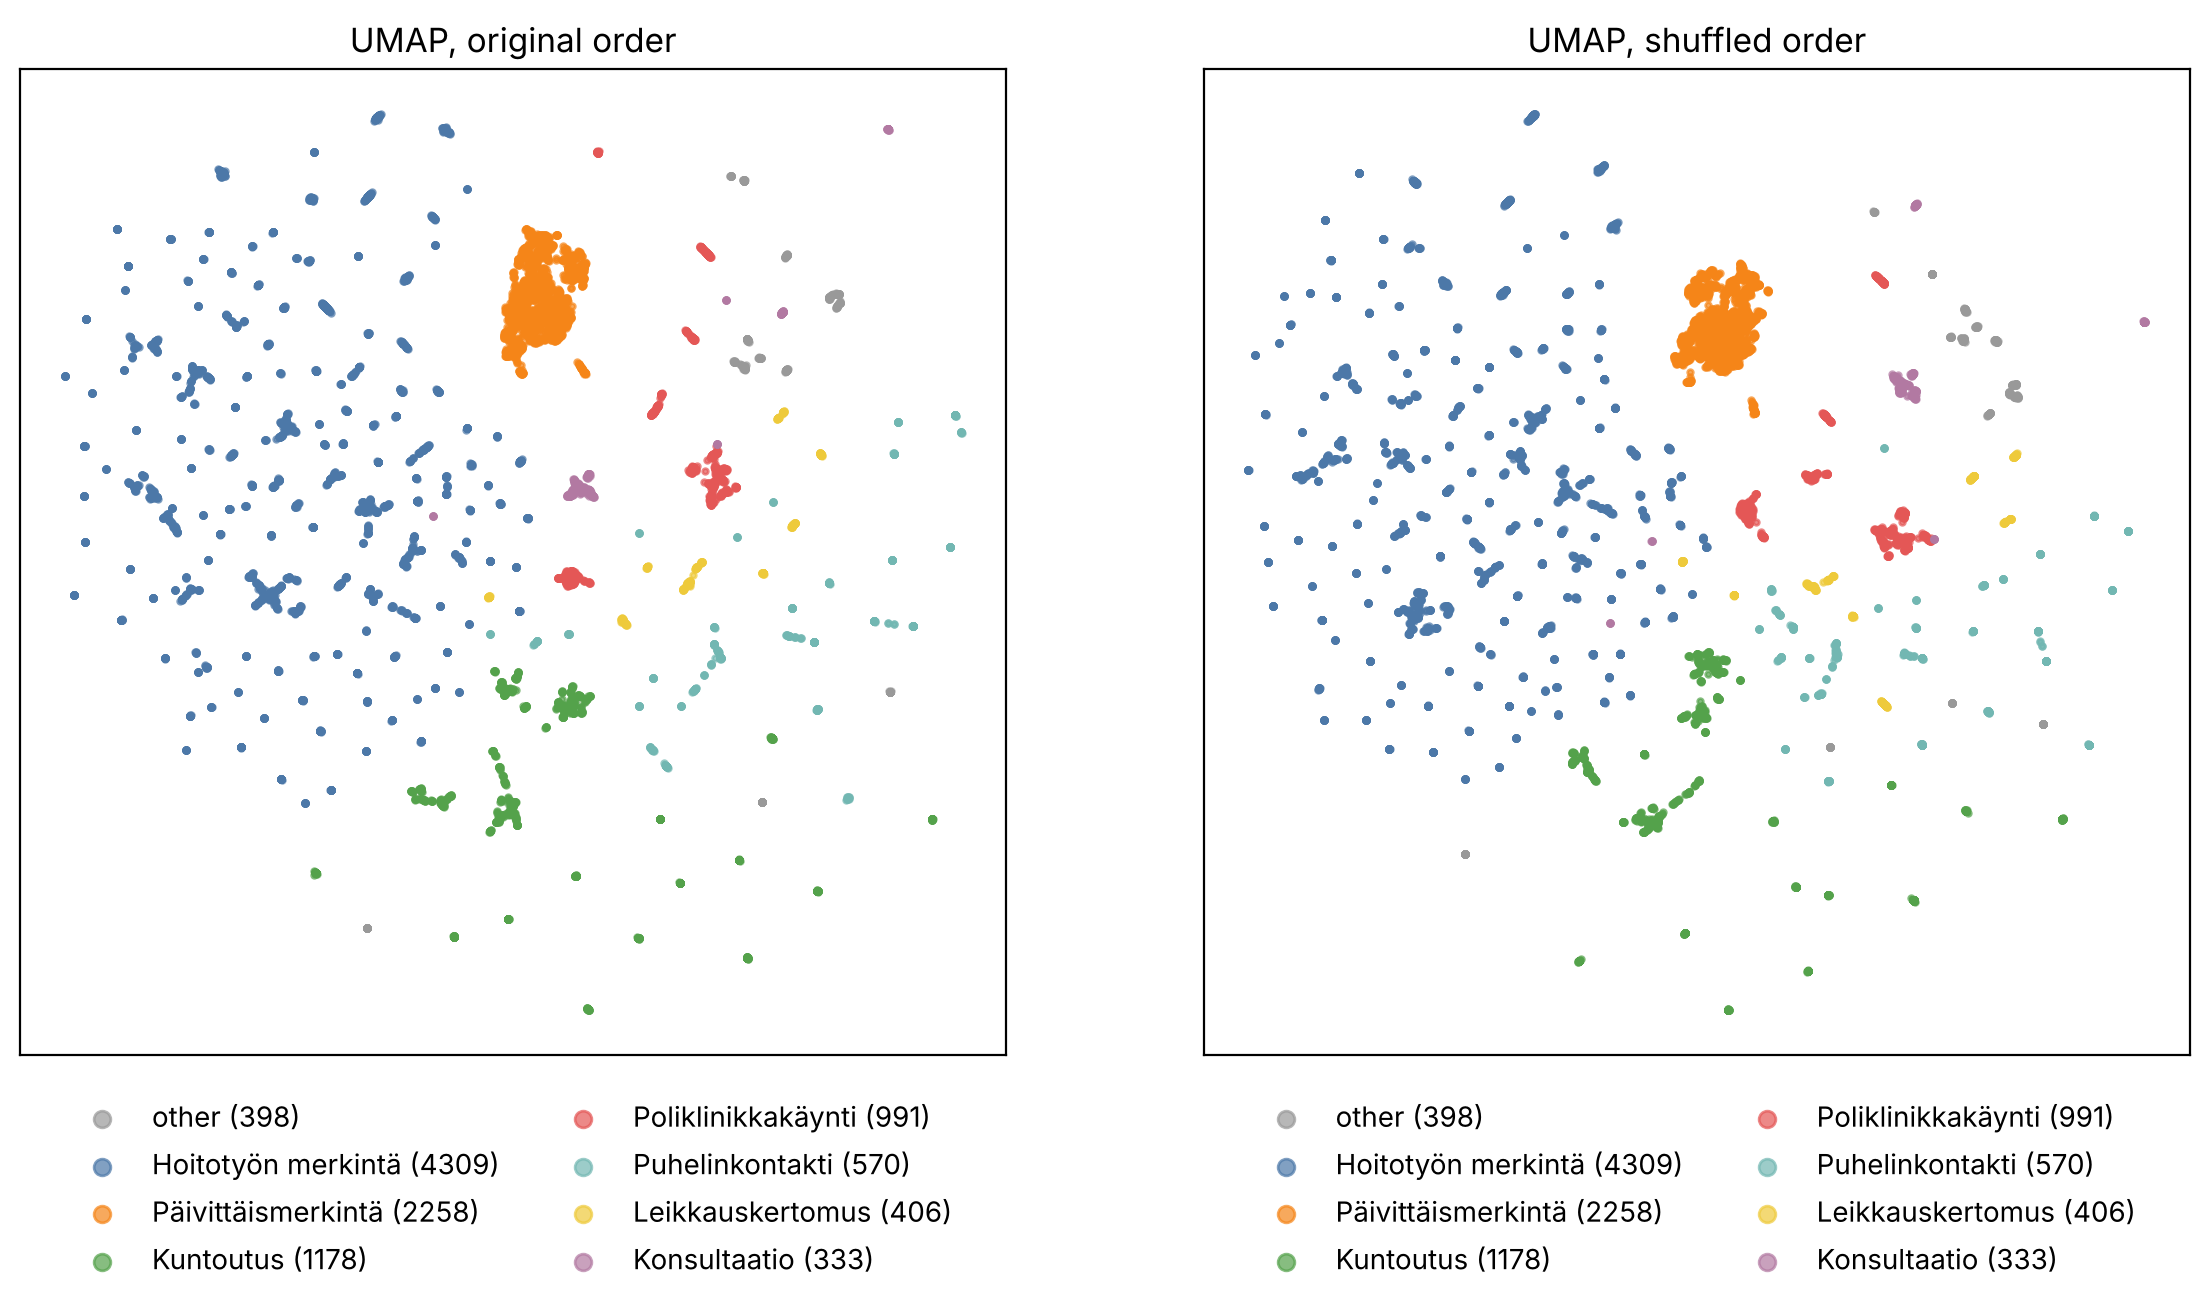

In [27]:
# Row order check (got a warning that this could affect the results): the main UMAP again with the rows shuffled, then put back in the original order
shuffled_order = np.random.default_rng(seed).permutation(len(embeddings))
umap_shuffled = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", init="pca", random_state=0, n_jobs=1).fit_transform(embeddings[shuffled_order])
umap_order_check = np.empty_like(umap_shuffled)
umap_order_check[shuffled_order] = umap_shuffled # Row n is note n again

# Agreement in the original and the shuffled order
for label in ["note_type", "diagnosis_code"]:
    agreement_original, used_labels = knn_agreement(main_umap, notes[label], notes["patient_id"], "euclidean")
    agreement_shuffled, used_labels = knn_agreement(umap_order_check, notes[label], notes["patient_id"], "euclidean")
    print("%s: %.2f in the original order, %.2f shuffled"
          % (label, np.mean(agreement_original), np.mean(agreement_shuffled)))

# Both pictures side by side, coloured by note type
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
plot_by_label(axes[0], main_umap, notes["note_type"], "note_type", "UMAP, original order")
plot_by_label(axes[1], umap_order_check, notes["note_type"], "note_type", "UMAP, shuffled order")
fig.savefig(results_folder + "/umap_row_order.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Note type and diagnosis mixed up? <a class="anchor" id="section_10"></a>

Some note types are much more common for some diagnoses, for example operation notes for patients who were operated on. A split by note type could then partly be a split by diagnosis, and the other way round. So we checked note type within each diagnosis group, and diagnosis code within each note type. We only used groups with at least 10 patients.

In [28]:
rows = []

# Note type within each diagnosis group
for group in sorted(notes["diagnosis_group"].dropna().unique()):
    in_group = (notes["diagnosis_group"] == group).to_numpy()
    if notes["patient_id"][in_group].nunique() < min_patients_per_code:
        continue
    agreement, used_labels = knn_agreement(embeddings[in_group], notes["note_type"][in_group], notes["patient_id"][in_group], "cosine")
    rows.append(["note type", "within " + group, len(used_labels), chance_level(used_labels), np.mean(agreement)])

# Diagnosis code within each note type
for note_type in sorted(notes["note_type"].unique()):
    in_type = (notes["note_type"] == note_type).to_numpy()
    with_code = notes["diagnosis_code"].notnull().to_numpy() # Notes that still have a code after Section 3
    if notes["patient_id"][in_type & with_code].nunique() < min_patients_per_code:
        continue
    if notes["diagnosis_code"][in_type & with_code].nunique() < 2: # One code only means agreement is always 1
        continue
    agreement, used_labels = knn_agreement(embeddings[in_type], notes["diagnosis_code"][in_type], notes["patient_id"][in_type], "cosine")
    rows.append(["diagnosis code", "within " + note_type, len(used_labels), chance_level(used_labels), np.mean(agreement)])

mixed_table = pd.DataFrame(rows, columns=["label", "subset", "notes", "chance", "agreement"])

# Short summary for the report, the full table stays in the environment
mixed_table["above_chance"] = mixed_table["agreement"] - mixed_table["chance"] # How far above chance each subset is
summary_table = mixed_table.groupby("label").agg(subsets=("subset", "count"),
                                                median_chance=("chance", "median"),
                                                median_agreement=("agreement", "median"),
                                                subsets_above_chance=("above_chance", lambda values: (values > 0).sum()))
summary_table.to_csv(results_folder + "/note_type_and_diagnosis_summary.csv")
summary_table.round(2)

,subsets,median_chance,median_agreement,subsets_above_chance
label,,,,
diagnosis code,9,0.16,0.42,7
note type,9,0.24,0.99,9


## 11. Clinical review <a class="anchor" id="section_11"></a>

Finally we wanted to know what actually separates the clusters. We split the main UMAP into clusters with k-means, and a clinician on the team read five random notes from each cluster and wrote down what set them apart: template, structure or content. On the real data this happened inside Acamedic, and only these categories were reported, never the text.

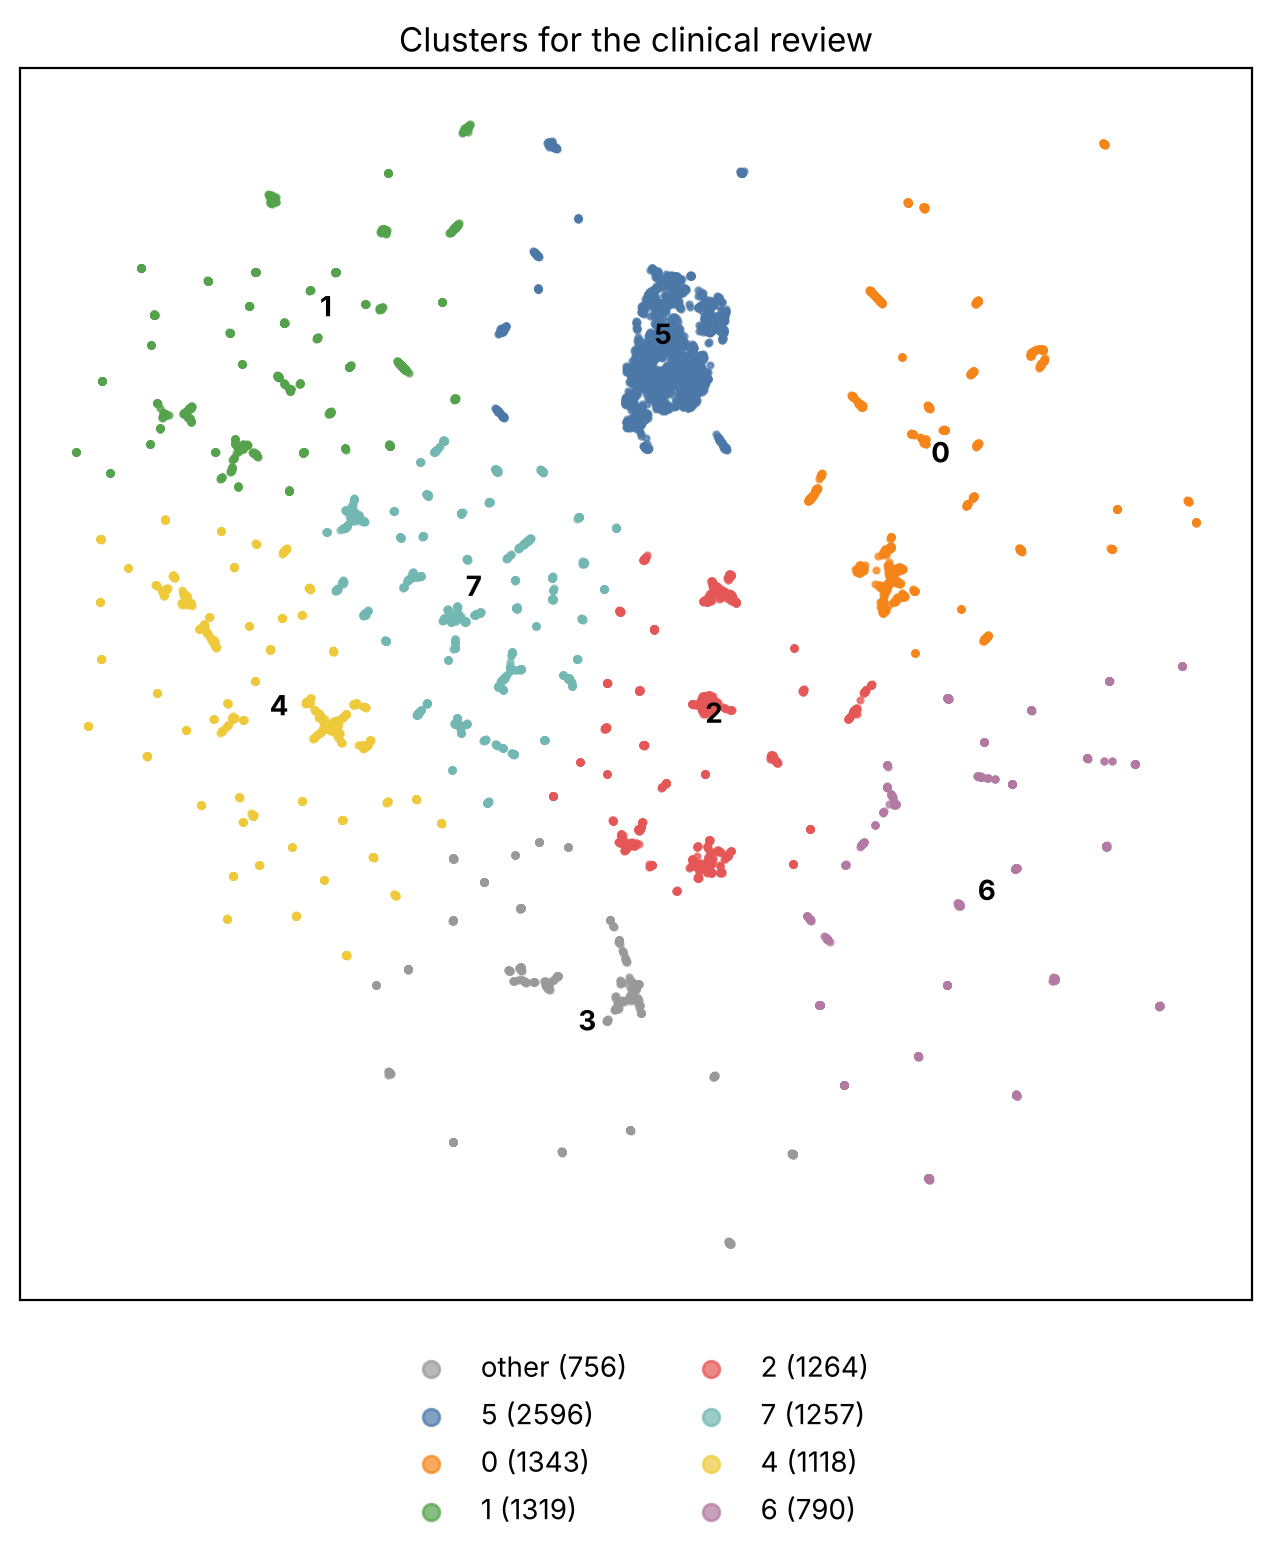

Cluster 0, Puhelinkontakti:
Puhelu: Kontrollisoitto: toipunut hyvin, ei vatsakipuja. Potilaalle annettu kirjalliset ohjeet ja yhteystiedot.

Cluster 0, Poliklinikkakäynti:
Tulosyy: Vatsa-aortan aneurysman seuranta Esitiedot: - Verenpainetauti - Tupakointi - Eteisvärinä Lääkitys: rivaroksabaani 20 mg x 1 /vrk, atorvastatiini 40 mg x 1 /vrk, ramipriili 5 mg x 1 /vrk Nykytila: Liikkuu omatoimisesti, kävelee päivittäin n. kilometrin. Vatsa-aortan aneurysma löytynyt sattum

Cluster 0, Poliklinikkakäynti:
Tsto: oik. alaraajan laskimovajaatoiminta. Aiemmin: ei merkittäviä perussairauksia. Lääk.: Ei säännöllistä lääkitystä. Anamn.: Kohjut pahentuneet raskauksien jälkeen. Säären alaosassa ihon tummumista ja kutinaa. Kohjussa ollut kipeä punoittava kovettuma, pinnallinen laskimotulehdus. St: Nilkoissa li

Cluster 0, Poliklinikkakäynti:
Tsto: Kontrollikäynti. Anamn.: jalkaterän pulssit tuntuvat. Kävelymatka pidentynyt selvästi, ei enää leposärkyä. Ark: Jatkoseuranta terveyskeskuksessa, ei säännöl

In [29]:
# Clusters in the main UMAP
kmeans = KMeans(n_clusters=number_of_clusters, random_state=seed, n_init=10)
notes["cluster"] = kmeans.fit_predict(main_umap)

fig, ax = plt.subplots(figsize=(8, 8))
plot_by_label(ax, main_umap, notes["cluster"].astype(str), "cluster", "Clusters for the clinical review")
for cluster in range(number_of_clusters):
    centre = kmeans.cluster_centers_[cluster]
    ax.text(centre[0], centre[1], str(cluster), fontweight="bold") # Cluster number in the middle
fig.savefig(results_folder + "/clusters.png", dpi=150, bbox_inches="tight")
plt.show()

# Five random notes from each cluster
review_notes = notes.groupby("cluster").sample(n=notes_per_cluster, random_state=seed)

if data_source == "synthetic":
    for index in range(review_notes.shape[0]):
        print("Cluster %d, %s:"
              % (review_notes["cluster"].iloc[index], review_notes["note_type"].iloc[index]))
        print(review_notes["text"].iloc[index][:300])
        print()
else:
    # On the real data the notes stayed inside Acamedic, in a folder that is not in git.
    # The clinician read them from internal/review_notes.csv, never in this notebook, so no text is in its outputs.
    os.makedirs("internal", exist_ok=True)
    review_notes[["cluster", "note_type", "text"]].to_csv("internal/review_notes.csv", index=False)
    print("Review notes saved to internal/review_notes.csv")

**What separated the clusters** (filled in by the clinician, no quotes from the notes)

| Cluster | What separates it (template, structure or content) |
|---|---|
| 0 | Longer texts all, leikkaus or dialyysi mentioned in some way in all of them, but very different clinical presentations. |
| 1 | All Lisäysmerkintä-type, with "Tehdyt toiminnnot:", for example "Määräysluetteloa muutettu" or "Kliininen merkintä kuitattu".|
| 2 | Short and medium long texts with no shared clinical theme, e.g. infection results, pain medication and imaging of the neck arteries. Not clinically the same at all. |
| 3 | Long texts, some oirekysely used in most of them, but very different ones (emergency department triage, dental service oirekysely).|
| 4 | Surgical procedure and hoitopäivän raportti texts. Quite structural both. |
| 5 | Dialysis or fisteloperations, so kidney procedures. |
| 6 | These happen to be all the same text, extremely short, as an example similar to "Hoitotyön päivittäismerkintä: ABI-mittaus".|
| 7 | All cases are limb ischemia of different kind, either the first visit or procedure text. |

## 12. Package versions <a class="anchor" id="section_12"></a>

In [ ]:
# Versions for the report
print("Python %s"
      % sys.version.split()[0])
packages = ["numpy", "pandas", "scikit-learn", "umap-learn", "matplotlib", "scipy", "requests", "torch"]
for package in packages:
    print("%s %s"
          % (package, version(package)))